# 03 · Predicción de abandono con Random Forest (Reto 3)

**Objetivo de negocio:** identificar qué interacciones (usuario, título) terminan en
**abandono** (el usuario no ve el título hasta el final) para priorizar acciones de retención
baratas (una notificación, una recomendación alternativa) y decidir qué datos habría que
recoger si el catálogo y el perfil de edad no bastan.

**Objetivo técnico:** Random Forest (modelo obligatorio) con `class_weight`, frente a
`DummyClassifier` y regresión logística, con partición **por usuario** (train / validación /
test), hiperparámetros por `RandomizedSearchCV` + `StratifiedGroupKFold` sobre train, *target
encoding* por título **dentro del `Pipeline`** (out-of-fold por usuario), prueba de
permutación para decidir estadísticamente si hay señal, calibración y umbral por costo
decididos en **validación**, y **una única** evaluación en test con IC 95 % bootstrap **por
usuario**. Se valida el método con **señal sembrada** (datos sintéticos donde el abandono sí
depende de la duración y de edad × género) para distinguir "el método no detecta" de "no hay
nada que detectar".

Una sección final (11) analiza el **techo de señal**: AUC de un oráculo con la regla generadora,
features de género exacto y segmentos de riesgo, con la salvedad explícita de que la regla se
conoció por inspección y de que el test ya se había evaluado.

**Nota sobre las cifras:** las cifras citadas en el texto corresponden a la **ejecución
completa** (`full`). Con `NP_FAST=1` (1.000 usuarios, búsqueda y remuestreos reducidos) varían y
valen las salidas de las celdas.

## Requisitos

- **Local:** Python ≥ 3.11 y `pip install -r requirements.txt` (o `python harness/init.py --install`, que crea el `.venv`).
- **Colab:** la celda de instalación de más abajo ejecuta `%pip install -q paquete==versión` **solo para lo que falte** (versión fijada). No se reinstalan `numpy`, `pandas`, `scikit-learn`, `matplotlib` ni `torch`: Colab ya los trae y cambiarlos obliga a reiniciar el entorno, lo que rompe «Ejecutar todo». Si no hay `data/raw`, la primera celda clona el repositorio público (o usa `NilePrime_AliGuerrero_codigo.zip` en `/content`).
- **Librerías de este notebook (versión de `requirements.txt`):** `pandas==2.3.3`, `numpy==2.3.5`, `scikit-learn==1.7.2`, `scipy==1.18.1`, `matplotlib==3.10.6`, `joblib==1.5.2`.

In [1]:
# Entorno: Colab o local y raíz del proyecto sin rutas absolutas (la instalación va en la celda siguiente).
REPO_URL = "https://github.com/aliguerreroj/nile-prime-ia.git"  # repositorio público con código y datos
ZIP_NAME = "NilePrime_AliGuerrero_codigo.zip"  # alternativa sin GitHub: subirlo a /content

import os
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
FAST = os.environ.get("NP_FAST") == "1"
SEED = 42

# Raíz = primera carpeta (cwd o sus padres) que contiene data/raw.
RAIZ = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "raw").is_dir()),
    None,
)
if RAIZ is None and EN_COLAB:
    # Colab: (a) zip en /content, (b) si no hay zip, git clone del repositorio público.
    import subprocess
    import zipfile

    _base = Path("/content")

    def _buscar_raiz():
        """Rutas directas primero; rglob solo como último recurso (sin recorrer /content/drive)."""
        for _d in (_base / "nile-prime-ia", _base / "NilePrime_AliGuerrero_codigo", _base):
            if (_d / "data" / "raw").is_dir():
                return _d
        for _sub in sorted(_base.iterdir()):
            if _sub.is_dir() and _sub.name not in ("drive", "sample_data"):
                for _raw in sorted(_sub.rglob("raw")):
                    if _raw.parent.name == "data" and _raw.is_dir():
                        return _raw.parent.parent
        return None

    for _z in sorted(_base.glob("NilePrime*codigo*.zip")) or sorted(_base.glob("*.zip")):
        with zipfile.ZipFile(_z) as _f:
            if any("data/raw/" in n for n in _f.namelist()):
                _f.extractall(_base)
                break
    RAIZ = _buscar_raiz()
    if RAIZ is None:
        try:
            _git = subprocess.run(["git", "clone", "--depth", "1", REPO_URL], cwd=_base,
                                  check=False, capture_output=True, text=True)
            _err = (_git.stderr or _git.stdout or "").strip().splitlines()
        except OSError as _e:
            _err = [str(_e)]
        RAIZ = _buscar_raiz()
        if RAIZ is None:
            raise RuntimeError(
                "No se pudo obtener el proyecto en Colab. Opción 1: comprueba la conexión a "
                "internet y vuelve a ejecutar (se clona " + REPO_URL + "). Opción 2: sube "
                + ZIP_NAME + " a /content y vuelve a ejecutar. Último error de git: "
                + (_err[-1] if _err else "sin salida")
            )
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra data/raw: ejecuta el notebook desde la carpeta del proyecto o una subcarpeta."
    )
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

In [2]:
# Instalación de dependencias (solo Colab, solo lo que falte; en local no instala nada).
# Colab ya trae todo lo demás; scipy se comprueba por si acaso.
import importlib.util

# paquete pip -> (módulo importable, versión fijada en requirements.txt)
_REQUISITOS = {"scipy": ("scipy", "1.18.1")}
_faltan = [f"{p}=={v}" for p, (m, v) in _REQUISITOS.items() if importlib.util.find_spec(m) is None]
if EN_COLAB and _faltan:
    for _spec in _faltan:
        # Equivalente a la magia:  %pip install -q scipy==1.18.1
        # (se usa run_line_magic porque jupytext no descomenta magias dentro de un bloque `if`).
        get_ipython().run_line_magic("pip", f"install -q {_spec}")  # noqa: F821
    print("Instalado:", ", ".join(_faltan))
else:
    print("Nada que instalar" + ("" if EN_COLAB else " (entorno local: usa requirements.txt)"))

Nada que instalar (entorno local: usa requirements.txt)


In [3]:
# Imports, semilla y configuración común.
import io
import json
import time
import warnings
from contextlib import contextmanager

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold

from src import data, evaluation as ev, features as ft, plots, synthetic as syn

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
np.random.seed(SEED)
plots.set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

MODO = "fast" if FAST else "full"
N_JOBS = min(16, os.cpu_count() or 1)
N_BOOT = 200 if FAST else 1000          # remuestreos bootstrap por usuario
N_PERM = 30 if FAST else 100            # permutaciones de etiquetas (>= 30)
N_ITER = 4 if FAST else 20              # configuraciones de RandomizedSearchCV
N_REP_IMP = 2 if FAST else 5            # repeticiones de la importancia por permutación
INTENSIDADES = [0.0, 1.0] if FAST else [0.0, 0.5, 1.0]  # señal sembrada
print(f"Modo: {MODO} | SEED = {SEED} | Colab: {EN_COLAB} | n_jobs = {N_JOBS}")
print(f"bootstrap = {N_BOOT} | permutaciones = {N_PERM} | n_iter = {N_ITER} | "
      f"intensidades sembradas = {INTENSIDADES}")
print(f"sklearn {sklearn.__version__} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scipy {scipy.__version__}")

TIEMPOS: dict[str, float] = {}


@contextmanager
def seccion(nombre: str):
    """Mide el tiempo de pared de una sección y lo guarda en ``TIEMPOS``."""
    t0 = time.perf_counter()
    yield
    TIEMPOS[nombre] = round(time.perf_counter() - t0, 1)


def fmt(m: dict, d: int = 4) -> str:
    """Formatea ``{"valor", "ic95"}`` como ``0.5123 [0.5012, 0.5234]``."""
    lo, hi = m["ic95"]
    return f"{m['valor']:.{d}f} [{lo:.{d}f}, {hi:.{d}f}]"


def nativo(o):
    """Convierte tipos de numpy a tipos nativos de Python para json."""
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    if isinstance(o, (np.bool_,)):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    raise TypeError(type(o))

Modo: full | SEED = 42 | Colab: False | n_jobs = 16
bootstrap = 1000 | permutaciones = 100 | n_iter = 20 | intensidades sembradas = [0.0, 0.5, 1.0]
sklearn 1.7.2 | numpy 2.3.5 | pandas 2.3.3 | scipy 1.18.1


## 1. Datos, tabla de features y partición por usuario

**Qué:** cargar las interacciones (`sin_duplicados=True`), unirlas por título con los
metadatos (`titulos_unicos=True`, 999 títulos) y construir la tabla con la clase positiva
**abandona** = `~Watched_to_End`.

**Features** (`src/features.py`): `Runtime`, `Released_Year`, `IMDB_Rating`, `No_of_Votes`,
`Meta_score` (con NaN: se imputa con la mediana **dentro del `Pipeline`**, ajustada con el
train de cada fold), géneros multi-hot (21), grupo de edad one-hot (3), interacción
edad × género (63 columnas binarias) y la tasa de abandono por título (sección 2).

**Partición por usuario:** 60 / 20 / 20 % de **usuarios** con `GroupShuffleSplit` encadenado.
Las filas de un mismo usuario no son independientes (comparten edad y hábitos); si cayeran
en train y test, el modelo podría "reconocer" al usuario. Se verifica con `assert` que
ningún usuario aparece en dos particiones. Roles: **train** ajusta (incluida la CV de la
búsqueda), **validación** elige calibración y umbral, **test** se toca una sola vez (sección 7).

**Limitaciones heredadas:** no hay marca de tiempo, tiempo visto, dispositivo ni sesión;
"Drishyam" son dos películas con el mismo título (~221 interacciones toman los atributos de
la de 2015). Las 63 columnas edad × género son el "contenido + edad" disponible.

In [4]:
with seccion("1_datos"):
    interacciones = data.load_interactions(sin_duplicados=True)
    metadatos = data.load_metadata(titulos_unicos=True)
    tabla = ft.construir_tabla(interacciones, metadatos)
    GENEROS = ft.lista_generos(metadatos)
    COLS = ft.columnas_entrada(GENEROS)
    idx = ft.particion_por_usuario(tabla, fracciones=(0.6, 0.2, 0.2), seed=SEED)
    tr, va, te = (tabla.iloc[idx[k]].reset_index(drop=True) for k in ("train", "validacion", "test"))
    ytr, yva, yte = (d[ft.COL_Y].to_numpy() for d in (tr, va, te))
    PI_TR = float(ytr.mean())

usuarios = {n: set(d[ft.COL_USUARIO]) for n, d in (("train", tr), ("validación", va), ("test", te))}
assert not (usuarios["train"] & usuarios["validación"])
assert not (usuarios["train"] & usuarios["test"])
assert not (usuarios["validación"] & usuarios["test"])

print(f"Tabla: {tabla.shape[0]:,} interacciones, {tabla[ft.COL_USUARIO].nunique():,} usuarios, "
      f"{tabla[ft.COL_TITULO].nunique()} títulos, {len(COLS) - 2} features + título + usuario")
print(pd.DataFrame({
    "filas": [len(d) for d in (tr, va, te)],
    "usuarios": [len(u) for u in usuarios.values()],
    "prevalencia_abandona": [ytr.mean(), yva.mean(), yte.mean()],
}, index=["train", "validación", "test"]).to_string())
print("Sin usuarios compartidos entre particiones: OK")
print(f"Meta_score con NaN en train: {tr['Meta_score'].isna().mean():.1%} (se imputa en el Pipeline)")

Tabla: 100,623 interacciones, 10,000 usuarios, 999 títulos, 92 features + título + usuario
            filas  usuarios  prevalencia_abandona
train       60187      6000                0.1030
validación  20244      2000                0.1016
test        20192      2000                0.1018
Sin usuarios compartidos entre particiones: OK
Meta_score con NaN en train: 15.6% (se imputa en el Pipeline)


**Conclusión técnica:** la prevalencia de la clase positiva es ≈ 10 % y es estable entre
particiones (la partición por usuario no estratifica, pero con miles de usuarios no se
desvía). Con ese desbalance, **ROC-AUC = 0,5** y **PR-AUC = prevalencia ≈ 0,10** son las
referencias de azar (la de PR-AUC no es 0,5). La exactitud no se usa: predecir siempre
"no abandona" daría ≈ 90 %.

**Implicación de negocio:** solo ≈ 1 de cada 10 visionados se abandona, así que cualquier
acción de retención se aplica sobre una minoría y su costo importa.

## 2. Features de historial sin fuga: tasa de abandono por título

**Qué:** la tasa histórica de abandono de un título es una feature natural de "popularidad del
abandono". Se implementa como *target encoding* (`TasaAbandonoTitulo`) suavizado hacia la
media global: `(suma_t + m·prior) / (n_t + m)` con `m = 20`; títulos no vistos reciben el
`prior`. **Vive dentro del `Pipeline`**: en cada fold de la CV se ajusta solo con el train de
ese fold, y los títulos del fold de validación se codifican con esas estadísticas.

**Sesgo del target encoding (y su solución).** Si se ajusta sobre las filas de train y se
aplica a esas mismas filas, cada fila contribuye a su propia codificación: la feature ya
contiene parte de la respuesta y el modelo sobreconfía en ella. `TasaAbandonoTitulo.fit_transform`
(lo que usa el `Pipeline` en train) codifica **out-of-fold por usuario** (5 pliegues
agrupados): cada fila se codifica con estadísticas que no incluyen su etiqueta ni la de su
usuario. `transform` (validación/test) usa el ajuste completo de train.

**Por qué NO se usa la tasa de abandono propia del usuario:** con la partición por usuario,
los usuarios de validación y test no existen en train, así que su historial no está en
entrenamiento; calcularla con sus propias etiquetas sería usar la variable objetivo del propio
usuario (fuga), y sin marca de tiempo no se puede separar pasado de futuro. En producción solo
existiría para usuarios con historial previo: sería otro problema (y otra feature) con datos
temporales, que no tenemos.

In [5]:
# Demostración del sesgo: correlación feature-etiqueta en TRAIN con la codificación ingenua
# (fit y transform sobre las mismas filas) frente a la out-of-fold, y con etiquetas barajadas
# (donde por construcción no hay relación: cualquier correlación es puro sesgo de autocontribución).
rng_demo = np.random.default_rng(SEED)
X_te_demo = tr[[ft.COL_TITULO, ft.COL_USUARIO]]
filas = []
for nombre, y_demo in (("etiquetas reales", ytr), ("etiquetas barajadas", rng_demo.permutation(ytr))):
    te_demo = ft.TasaAbandonoTitulo(suavizado=20.0)
    oof = te_demo.fit_transform(X_te_demo, y_demo).ravel()
    ingenua = ft.TasaAbandonoTitulo(suavizado=20.0).fit(X_te_demo, y_demo).transform(X_te_demo).ravel()
    filas.append({"etiquetas": nombre,
                  "corr ingenua (con autocontribución)": np.corrcoef(ingenua, y_demo)[0, 1],
                  "corr out-of-fold": np.corrcoef(oof, y_demo)[0, 1]})
print(pd.DataFrame(filas).to_string(index=False))

          etiquetas  corr ingenua (con autocontribución)  corr out-of-fold
   etiquetas reales                               0.1353            0.0123
etiquetas barajadas                               0.1282           -0.0000


**Conclusión técnica:** la codificación ingenua se correlaciona con la etiqueta incluso cuando
esta está **barajada** (r ≈ 0,13: puro sesgo de autocontribución, que crece al bajar el número
de interacciones por título); la out-of-fold queda en r ≈ 0,000 con las etiquetas barajadas y en
r ≈ 0,012 con las reales (la correlación real, muy pequeña, de la tasa del título con el
abandono). La solución out-of-fold elimina el sesgo por construcción y un test unitario
(`tests/test_features.py`) lo cubre. Matiz: la codificación out-of-fold usa el 80 % de train por
fila, algo más ruidosa que la de `transform`; es el coste conocido de evitar la fuga.

**Implicación de negocio:** la "tasa histórica de abandono del título" solo es una señal
honesta si se calcula con datos que el modelo no usa para predecir esa misma fila.

## 3. Búsqueda de hiperparámetros del Random Forest (CV por usuario sobre train)

**Qué:** `RandomizedSearchCV` sobre el `Pipeline` completo (imputación + target encoding +
RF) con `StratifiedGroupKFold(3, shuffle=True)` **agrupado por usuario**: cada fold conserva
la prevalencia de abandono y no comparte usuarios entre su train y su validación. Métrica de
selección declarada: **ROC-AUC** (independiente del umbral y del desbalance; la PR-AUC es
más ruidosa con ≈ 10 % de positivos). Se prueba `n_iter` configuraciones del espacio de
abajo (reducido en FAST).

**Desbalance:** `class_weight` (`balanced` o `balanced_subsample`) forma parte del espacio. Efecto
colateral conocido: las probabilidades quedan infladas (≈ 0,5 de media en lugar de ≈ 0,10), por
lo que se calibran en la sección 5. El espacio limita `n_estimators` y `max_depth` para
mantener el costo controlado; `min_samples_leaf` alto regulariza (con poca señal, los árboles
profundos memorizan ruido).

**Reutilización:** los hiperparámetros elegidos aquí se reutilizan **sin repetir la búsqueda** en
la prueba de permutación y en la validación con señal sembrada (sección 10).

In [6]:
if FAST:
    ESPACIO = {"n_estimators": [50, 100], "max_depth": [4, 8], "min_samples_leaf": [25, 50],
               "max_features": ["sqrt"], "max_samples": [0.5],
               "class_weight": ["balanced_subsample"]}
else:
    ESPACIO = {"n_estimators": [100, 200, 300], "max_depth": [4, 6, 8, 12],
               "min_samples_leaf": [10, 25, 50, 100], "max_features": ["sqrt", 0.3, 0.5],
               "max_samples": [0.3, 0.6, None],
               "class_weight": ["balanced", "balanced_subsample"]}
N_COMBINACIONES = int(np.prod([len(v) for v in ESPACIO.values()]))
CV_FOLDS = 3
SCORING = "roc_auc"

pipe_rf = ft.crear_pipeline(RandomForestClassifier(random_state=SEED, n_jobs=N_JOBS), GENEROS)
cv = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
busqueda = RandomizedSearchCV(
    pipe_rf, {f"clf__{k}": v for k, v in ESPACIO.items()}, n_iter=min(N_ITER, N_COMBINACIONES),
    scoring=SCORING, cv=cv, random_state=SEED, n_jobs=1, refit=True,
)
with seccion("3_busqueda_rf"):
    busqueda.fit(tr[COLS], ytr, groups=tr[ft.COL_USUARIO])
rf_final = busqueda.best_estimator_
MEJORES = {k.removeprefix("clf__"): v for k, v in busqueda.best_params_.items()}
T_REFIT = float(busqueda.refit_time_)

res = pd.DataFrame(busqueda.cv_results_).sort_values("rank_test_score")
cols_res = ["mean_test_score", "std_test_score"] + [c for c in res if c.startswith("param_")]
print(f"Espacio: {N_COMBINACIONES} combinaciones; se evalúan {busqueda.n_iter} x {CV_FOLDS} folds "
      f"({SCORING}). Tiempo de búsqueda: {TIEMPOS['3_busqueda_rf']:.0f} s")
print(res[cols_res].head(5).rename(columns=lambda c: c.removeprefix("param_clf__")).to_string())
print(f"\nElegidos: {MEJORES} | ROC-AUC CV (train) = {busqueda.best_score_:.4f}")
print(f"Rango de ROC-AUC en CV entre configuraciones: [{res['mean_test_score'].min():.4f}, "
      f"{res['mean_test_score'].max():.4f}]")

Espacio: 864 combinaciones; se evalúan 20 x 3 folds (roc_auc). Tiempo de búsqueda: 83 s
    mean_test_score  std_test_score  n_estimators  min_samples_leaf max_samples max_features  max_depth        class_weight
11           0.5205          0.0035           200               100      0.6000         sqrt         12  balanced_subsample
14           0.5182          0.0055           200               100        None         sqrt          8  balanced_subsample
10           0.5177          0.0044           100               100        None       0.3000         12            balanced
1            0.5168          0.0052           100                10      0.3000       0.5000          8  balanced_subsample
13           0.5163          0.0045           300                50        None         sqrt          4  balanced_subsample

Elegidos: {'n_estimators': 200, 'min_samples_leaf': 100, 'max_samples': 0.6, 'max_features': 'sqrt', 'max_depth': 12, 'class_weight': 'balanced_subsample'} | ROC-AUC C

**Conclusión técnica:** los ROC-AUC de CV de las 20 configuraciones se agrupan en 0,510–0,521
(desviación entre folds ≈ 0,004–0,006): la mejor supera a la peor en ≈ 2 desviaciones, es decir,
**la búsqueda no encuentra una región del espacio que destaque**; todas las configuraciones
rinden ≈ 0,52, un valor apenas por encima del azar. Se elige la de mayor media de CV
(`min_samples_leaf = 100` y `max_depth = 12`, regularización fuerte) sin afirmar que sea mejor que las
vecinas. Cuando la señal es tan débil, optimizar hiperparámetros apenas mueve el resultado.

**Implicación de negocio:** ningún ajuste del modelo rescata una señal que los datos
disponibles contienen en una cantidad mínima.

## 4. Baselines y primera lectura en validación; prueba de permutación

**Baselines** (mismas features, mismo particionado): `DummyClassifier(strategy="prior")`
(probabilidad constante = prevalencia → ROC-AUC = 0,5 exacto) y regresión logística con
`class_weight="balanced"`, imputación y escalado dentro del `Pipeline` (baseline lineal
informativo: si no supera al azar, tampoco lo hará un modelo no lineal sobre las mismas
features salvo por interacciones no lineales).

**Prueba de permutación (¿hay señal?).** Hipótesis nula H0: *las etiquetas son independientes
de las features*. Se baraja `ytr` (solo train, B veces), se ajusta el **mismo** pipeline con los
hiperparámetros ya fijados (incluido el target encoding, que se recalcula con las etiquetas
barajadas) y se mide el ROC-AUC en **validación con sus etiquetas reales**. La distribución
resultante es el AUC que produce el procedimiento cuando no hay relación (incluye el ruido del
modelo y del conjunto de validación). El p-valor empírico es
`(1 + #{AUC_nulo ≥ AUC_observado}) / (1 + B)`. El barajado es a nivel de fila: rompe también
cualquier dependencia usuario-etiqueta; es válido porque las features no contienen el
identificador de usuario y la dependencia intra-usuario de la etiqueta es despreciable (r ≈
0,006 con la tasa del usuario, notebook 00).

In [7]:
def proba(pipe, df):
    """Probabilidad de la clase 'abandona' de un pipeline ya ajustado."""
    return pipe.predict_proba(df[COLS])[:, 1]


with seccion("4_baselines"):
    dummy = DummyClassifier(strategy="prior").fit(tr[COLS], ytr)
    pipe_lr = ft.crear_pipeline(
        LogisticRegression(class_weight="balanced", max_iter=1000), GENEROS, escalar=True
    ).fit(tr[COLS], ytr)
    p_rf_va = proba(rf_final, va)
    AUC_VA = {
        "Dummy (prior)": roc_auc_score(yva, proba(dummy, va)),
        "Regresión logística": roc_auc_score(yva, proba(pipe_lr, va)),
        "Random Forest": roc_auc_score(yva, p_rf_va),
    }
print("ROC-AUC en validación (único uso: lectura previa, no se decide con ella):")
for k, v in AUC_VA.items():
    print(f"  {k:22s} {v:.4f}")

ROC-AUC en validación (único uso: lectura previa, no se decide con ella):
  Dummy (prior)          0.5000
  Regresión logística    0.5238
  Random Forest          0.5208


AUC observado (validación): 0.5208
AUC nulo (100 permutaciones): media 0.5029 | sd 0.0085 | [0.4863, 0.5177] | máx 0.5220
p-valor empírico (unilateral, +1) = 0.0198  (mínimo alcanzable con B = 100: 0.0099)


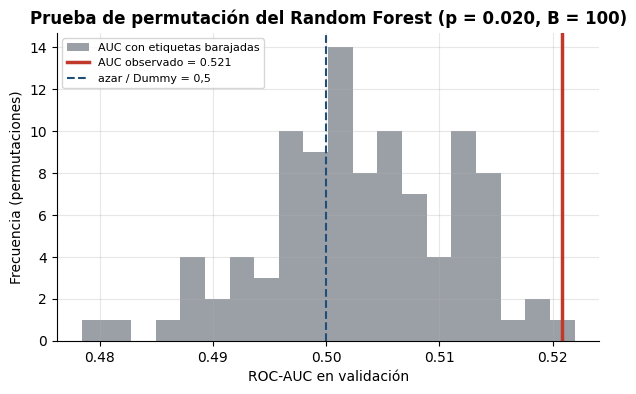

In [8]:
with seccion("4_permutacion"):
    AUC_OBS = AUC_VA["Random Forest"]
    rng_perm = np.random.default_rng(SEED)
    nulos = np.empty(N_PERM)
    for b in range(N_PERM):
        pipe_b = clone(rf_final).fit(tr[COLS], rng_perm.permutation(ytr))
        nulos[b] = roc_auc_score(yva, proba(pipe_b, va))
P_PERM = ev.p_valor_permutacion(AUC_OBS, nulos)
print(f"AUC observado (validación): {AUC_OBS:.4f}")
print(f"AUC nulo ({N_PERM} permutaciones): media {nulos.mean():.4f} | sd {nulos.std(ddof=1):.4f} | "
      f"[{np.quantile(nulos, 0.025):.4f}, {np.quantile(nulos, 0.975):.4f}] | máx {nulos.max():.4f}")
print(f"p-valor empírico (unilateral, +1) = {P_PERM:.4f}  "
      f"(mínimo alcanzable con B = {N_PERM}: {1 / (1 + N_PERM):.4f})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(nulos, bins=20, color=plots.PALETA["neutro"], alpha=0.85, label="AUC con etiquetas barajadas")
ax.axvline(AUC_OBS, color=plots.PALETA["referencia"], lw=2.5, label=f"AUC observado = {AUC_OBS:.3f}")
ax.axvline(0.5, color=plots.PALETA["principal"], ls="--", label="azar / Dummy = 0,5")
ax.set_xlabel("ROC-AUC en validación")
ax.set_ylabel("Frecuencia (permutaciones)")
ax.set_title(f"Prueba de permutación del Random Forest (p = {P_PERM:.3f}, B = {N_PERM})")
ax.legend(fontsize=8)
plots.save_fig(fig, "03_prueba_permutacion")
plt.show()

**Conclusión técnica:** en validación el RF obtiene ROC-AUC 0,5208 y la regresión logística
0,5238 (el Dummy, 0,5000 exacto). La distribución nula (100 permutaciones de etiquetas) está
centrada en 0,503 con sd 0,0085 (IC 95 % del nulo [0,486; 0,518], máx 0,522): el AUC observado
queda en la cola, con **p = 0,020** (el mínimo alcanzable con B = 100 es 0,0099). Se rechaza
H0 al 5 %: hay **evidencia estadística de una señal débil** (coherente con el efecto pequeño pero
detectable de la edad, V de Cramér 0,015, y con el AUC ≈ 0,52 de la CV). Pero la magnitud es
mínima: un AUC de 0,52 equivale a ordenar bien un par (abandona, no abandona) el 52 % de las veces
frente al 50 % del azar. El p-valor tiene resolución limitada por B y se calcula sobre una sola
validación (≈ 2.000 positivos); la regresión logística, más simple, rinde igual. Esta prueba
contrasta "señal frente a nada", no "RF frente a regresión logística" (eso, en la sección 6).

**Implicación de negocio:** existe un rastro de señal en edad y catálogo, pero tan pequeño que
la pregunta relevante para el negocio no es si es distinto de cero sino cuánto aporta (sección 6).

## 5. Calibración y umbral de decisión (en validación)

**Calibración.** `class_weight` infla las probabilidades (el modelo "cree" que la prevalencia es
≈ 50 %). Se comparan, por **Brier score en validación**, tres versiones: sin calibrar,
sigmoide (Platt sobre `logit(p)`) e isotónica. Para no evaluar un calibrador sobre los datos
con los que se ajusta, la comparación usa **predicciones calibradas out-of-fold por usuario**
(`calibrar_oof_por_grupos`, 5 pliegues agrupados) dentro de la validación. El calibrador elegido
se reajusta después con **toda** la validación y es el que se aplica al test (el test no
interviene). Referencia: predecir siempre la prevalencia de train (Brier = π(1−π) ≈ 0,092).

**Matriz de costos (decisión de negocio, confirmada por Ali; no se estima de los datos):**
`C_FN = 3`: no detectar a un usuario que abandonará (pérdida de engagement y riesgo de baja).
`C_FP = 1`: acción de retención innecesaria, pero barata (una notificación o una recomendación
alternativa). Con probabilidades calibradas, la regla de Bayes marca a un usuario si
`p > C_FP / (C_FP + C_FN) = 0,25`. El umbral se elige en validación minimizando el **costo
esperado por interacción** `(C_FP·FP + C_FN·FN) / n`, con desempate hacia el umbral de Bayes, y
se compara con el que maximiza **F2** (el recall pesa el doble que la precisión, coherente con
FN más caro). Nunca 0,5 por defecto. Se informa la sensibilidad a razones FN:FP de 1:1, 2:1, 3:1 y 5:1.

**Análisis de degeneración (hipótesis a verificar).** Sin señal, una predicción calibrada es
≈ π ≈ 0,10 para todos, bajo el umbral de Bayes de 0,25: la política óptima es **no marcar a
nadie** (costo π·C_FN ≈ 0,31 por interacción frente a (1−π)·C_FP ≈ 0,90 de marcar a todos).
Marcar a todos solo compensa con una razón FN:FP > (1−π)/π ≈ 8,8. F2, en cambio, tiende a
marcar a todos (el recall máximo es "gratis" en F2 cuando la precisión no discrimina).

In [9]:
with seccion("5_calibracion_umbral"):
    g_va = va[ft.COL_USUARIO].to_numpy()
    CANDIDATOS = ["sin calibrar", "sigmoide", "isotonica"]
    p_va_cal = {"sin calibrar": p_rf_va}
    for met in ("sigmoide", "isotonica"):
        p_va_cal[met] = ev.calibrar_oof_por_grupos(met, p_rf_va, yva, g_va, n_splits=5)
    brier_va = {k: float(np.mean((p - yva) ** 2)) for k, p in p_va_cal.items()}
    BRIER_REF_VA = float(np.mean((yva - PI_TR) ** 2))
    CAL_ELEGIDA = min(brier_va, key=brier_va.get)
    p_va_elegida = p_va_cal[CAL_ELEGIDA]
    if CAL_ELEGIDA == "sin calibrar":
        calibrador = lambda q: np.asarray(q, dtype=float)  # noqa: E731
    else:
        calibrador = ev.ajustar_calibrador(CAL_ELEGIDA, p_rf_va, yva)

    C_FP, C_FN = 1.0, 3.0
    BAYES = C_FP / (C_FP + C_FN)
    grid = np.unique(np.concatenate([
        np.linspace(0.01, 0.99, 99),
        np.quantile(p_va_elegida, np.linspace(0.005, 0.995, 199)),
    ]))
    sel = ev.umbral_por_costo(yva, p_va_elegida, C_FP, C_FN, grid, referencia=BAYES)
    UMBRAL = sel["umbral"]

    def f_beta(y, p, grid, beta=2.0):
        """F-beta de la clase positiva para cada umbral de ``grid`` (decisión ``p >= t``)."""
        y = np.asarray(y).astype(bool)
        salida = []
        for t in grid:
            pred = p >= t
            tp, fp, fn = (y & pred).sum(), (~y & pred).sum(), (y & ~pred).sum()
            den = (1 + beta**2) * tp + beta**2 * fn + fp
            salida.append((1 + beta**2) * tp / den if den > 0 else 0.0)
        return np.array(salida)

    f2_va = f_beta(yva, p_va_elegida, grid)
    UMBRAL_F2 = float(grid[int(np.argmax(f2_va))])
    PI_VA = float(yva.mean())
    RAZONES = {"1:1": 1.0, "2:1": 2.0, "3:1 (base)": 3.0, "5:1": 5.0}
    sensib = {}
    for etq, r in RAZONES.items():
        s = ev.umbral_por_costo(yva, p_va_elegida, 1.0, r, grid, referencia=1.0 / (1.0 + r))
        marcados = float((p_va_elegida >= s["umbral"]).mean())
        sensib[etq] = {"umbral": s["umbral"], "umbral_bayes": 1.0 / (1.0 + r),
                       "costo": s["costo"], "pct_marcados": marcados,
                       "costo_marcar_a_todos": (1 - PI_VA) * 1.0, "costo_no_marcar": PI_VA * r}

print("Brier en validación (out-of-fold por usuario para las calibradas):")
for k, v in brier_va.items():
    print(f"  {k:13s} {v:.5f}" + ("   <- elegida" if k == CAL_ELEGIDA else ""))
print(f"  referencia (predecir prevalencia de train): {BRIER_REF_VA:.5f}")
print(f"\nProbabilidad media predicha: sin calibrar {p_rf_va.mean():.3f} -> "
      f"{CAL_ELEGIDA} {p_va_elegida.mean():.3f} (prevalencia real {PI_VA:.3f})")
print(f"Probabilidades calibradas (validación): mín {p_va_elegida.min():.3f} | "
      f"p95 {np.quantile(p_va_elegida, 0.95):.3f} | máx {p_va_elegida.max():.3f} | "
      f"sd {p_va_elegida.std():.4f}")
print(f"Interacciones con p calibrada >= {BAYES:.2f} (umbral de Bayes): "
      f"{(p_va_elegida >= BAYES).sum()} de {len(yva)}")
print(f"\nUmbral por costo (C_FP={C_FP:g}, C_FN={C_FN:g}) = {UMBRAL:.3f} | "
      f"costo {sel['costo']:.4f} | marca al {(p_va_elegida >= UMBRAL).mean():.1%}")
print(f"Umbral que maximiza F2 = {UMBRAL_F2:.3f} (F2 = {f2_va.max():.4f}) | "
      f"marca al {(p_va_elegida >= UMBRAL_F2).mean():.1%} | "
      f"costo con ese umbral {ev.costo_esperado(yva, p_va_elegida, UMBRAL_F2, C_FP, C_FN):.4f}")
print(f"Costos de las políticas triviales: no marcar a nadie {PI_VA * C_FN:.4f} | "
      f"marcar a todos {(1 - PI_VA) * C_FP:.4f} | razón de equilibrio (1-π)/π = {(1 - PI_VA) / PI_VA:.2f}")
print("\nSensibilidad a la razón de costos FN:FP (validación):")
print(pd.DataFrame(sensib).T.to_string())

Brier en validación (out-of-fold por usuario para las calibradas):
  sin calibrar  0.24207
  sigmoide      0.09122
  isotonica     0.09115   <- elegida
  referencia (predecir prevalencia de train): 0.09129

Probabilidad media predicha: sin calibrar 0.490 -> isotonica 0.102 (prevalencia real 0.102)
Probabilidades calibradas (validación): mín 0.000 | p95 0.123 | máx 0.500 | sd 0.0196
Interacciones con p calibrada >= 0.25 (umbral de Bayes): 73 de 20244

Umbral por costo (C_FP=1, C_FN=3) = 0.250 | costo 0.3035 | marca al 0.4%
Umbral que maximiza F2 = 0.010 (F2 = 0.3611) | marca al 99.9% | costo con ese umbral 0.8978
Costos de las políticas triviales: no marcar a nadie 0.3048 | marcar a todos 0.8984 | razón de equilibrio (1-π)/π = 8.84

Sensibilidad a la razón de costos FN:FP (validación):
            umbral  umbral_bayes  costo  pct_marcados  costo_marcar_a_todos  costo_no_marcar
1:1         0.5100        0.5000 0.1016        0.0000                0.8984           0.1016
2:1         0.2900

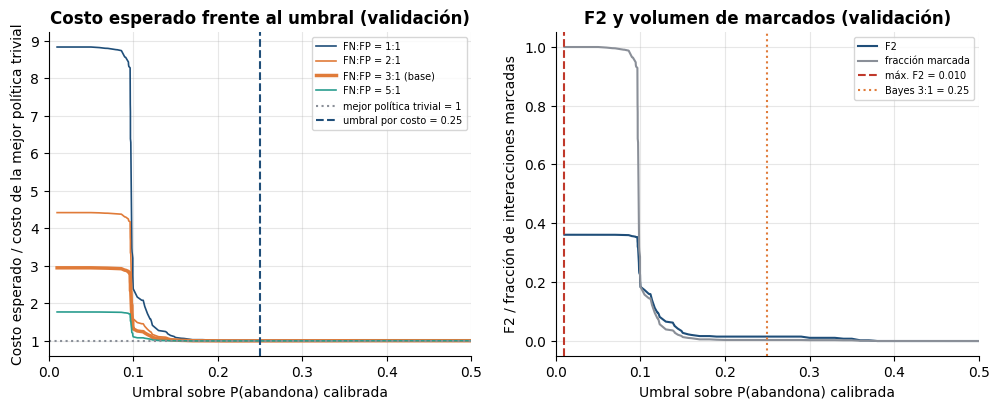

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axs[0]
for etq, r in RAZONES.items():
    t, c = ev.curva_costo_umbral(yva, p_va_elegida, 1.0, r, grid)
    mejor_trivial = min(PI_VA * r, 1 - PI_VA)
    ax.plot(t, c / mejor_trivial, label=f"FN:FP = {etq}", lw=2.5 if "base" in etq else 1.2,
            color=plots.PALETA["enfasis"] if "base" in etq else None)
ax.axhline(1.0, color=plots.PALETA["neutro"], ls=":", label="mejor política trivial = 1")
ax.axvline(UMBRAL, color=plots.PALETA["principal"], ls="--", label=f"umbral por costo = {UMBRAL:.2f}")
ax.set_xlim(0, 0.5)
ax.set_xlabel("Umbral sobre P(abandona) calibrada")
ax.set_ylabel("Costo esperado / costo de la mejor política trivial")
ax.set_title("Costo esperado frente al umbral (validación)")
ax.legend(fontsize=7)
ax = axs[1]
ax.plot(grid, f2_va, color=plots.PALETA["principal"], label="F2")
ax.plot(grid, [(p_va_elegida >= t).mean() for t in grid], color=plots.PALETA["neutro"],
        label="fracción marcada")
ax.axvline(UMBRAL_F2, color=plots.PALETA["referencia"], ls="--", label=f"máx. F2 = {UMBRAL_F2:.3f}")
ax.axvline(BAYES, color=plots.PALETA["enfasis"], ls=":", label=f"Bayes 3:1 = {BAYES:.2f}")
ax.set_xlim(0, 0.5)
ax.set_xlabel("Umbral sobre P(abandona) calibrada")
ax.set_ylabel("F2 / fracción de interacciones marcadas")
ax.set_title("F2 y volumen de marcados (validación)")
ax.legend(fontsize=7)
plots.save_fig(fig, "03_umbral")
plt.show()

**Conclusión técnica:** sin calibrar, el RF (con `class_weight`) predice en media 0,49 frente a una
prevalencia de 0,10 y su Brier es 0,242; la calibración isotónica (la de menor Brier en
validación out-of-fold, 0,09115 frente a 0,09122 de la sigmoide: prácticamente empatadas) lo
baja a 0,0912, es decir, **al nivel de la referencia de predecir siempre la prevalencia** (0,0913).
Las probabilidades calibradas se concentran alrededor de π (p95 = 0,123; sd = 0,02) y solo 73 de
20.244 interacciones de validación (0,36 %) alcanzan el umbral de Bayes de 0,25; la isotónica
genera además "escalones" de pocos casos en los extremos (máx 0,5), que son ruido ajustado. El
umbral de menor costo en validación (0,25, en el límite de Bayes) marca solo a ese 0,4 % y
reduce el costo de 0,3048 a 0,3035 (−0,4 %): una mejora ínfima sobre la política trivial "no
marcar a nadie", que se verifica en test (sección 6) y que no se sostiene. Es la
**degeneración esperada**: la política óptima es, en la práctica, no marcar a nadie. Con
1:1 no se marca a nadie (umbral 0,51, por encima de la máxima probabilidad calibrada, 0,5) y
con 2:1 solo el 0,36 %; con 5:1 sigue siendo el 0,36 % (umbral 0,20 y no el de Bayes 0,167,
porque las probabilidades isotónicas son escalonadas y el costo es igual en ese tramo), ya que
la razón de equilibrio para marcar a todos es (1−π)/π ≈ 8,8. El umbral se eligió con
probabilidades calibradas fuera de pliegue y al test se aplica el calibrador ajustado con toda
la validación: el optimismo es mínimo (en test marca el mismo 0,36 %). F2 elige un umbral de 0,01 que **marca al
99,9 %** de las interacciones (recall ≈ 1 con precisión ≈ prevalencia) a un costo de 0,898, casi
el triple del de no marcar.

**Implicación de negocio:** con los costos acordados (3:1) el modelo no justifica ninguna
acción individual de retención, y F2 aconsejaría contactar a prácticamente todos los usuarios
a un costo tres veces mayor que no hacer nada.

## 6. Evaluación única en test, con IC 95 % bootstrap por usuario

**Qué:** a partir de aquí se toca el test **por primera y última vez**, con modelo,
calibrador y umbral fijados en validación. Métricas del RF: ROC-AUC y PR-AUC
(*average precision*; referencia de azar = prevalencia ≈ 0,10, **no** 0,5) del ranking del
modelo, calculadas sobre la probabilidad sin calibrar (son invariantes a una calibración
monótona; la sigmoide de Platt solo se admite con pendiente positiva, ver `ajustar_calibrador`),
Brier del modelo calibrado, y F1 y recall de 'abandona' al umbral por costo. IC 95 % por **bootstrap por usuario** (`N_BOOT` remuestreos de
usuarios completos con reemplazo, porque las filas de un usuario no son independientes);
los modelos comparten remuestreos, de modo que las **diferencias de AUC son pareadas**.

F1 y recall se informan en el umbral por costo (decisión del negocio) y, como contraste, en
el de F2. Si el umbral por costo no marca a nadie, F1 = recall = 0 por construcción: no es un
fallo del cálculo sino el resultado de la política óptima sin señal.

In [11]:
with seccion("6_test"):
    p_rf_te = proba(rf_final, te)
    p_cal_te = calibrador(p_rf_te)
    p_lr_te = proba(pipe_lr, te)
    p_du_te = proba(dummy, te)
    g_te = te[ft.COL_USUARIO].to_numpy()

    N_RF, N_RF_RAW, N_LR, N_DU = "Random Forest (calibrado)", "Random Forest (sin calibrar)", \
        "Regresión logística", "Dummy (prior)"
    punt = {N_RF: p_cal_te, N_RF_RAW: p_rf_te, N_LR: p_lr_te, N_DU: p_du_te}
    b1 = ev.bootstrap_por_grupos(yte, punt, g_te, umbrales={N_RF: UMBRAL}, referencia=N_DU,
                                 n_boot=N_BOOT, seed=SEED)
    b2 = ev.bootstrap_por_grupos(yte, {N_RF_RAW: p_rf_te, N_LR: p_lr_te}, g_te, referencia=N_LR,
                                 n_boot=N_BOOT, seed=SEED)
    b3 = ev.bootstrap_por_grupos(yte, {N_RF: p_cal_te}, g_te, umbrales={N_RF: UMBRAL_F2},
                                 n_boot=N_BOOT, seed=SEED)
    MET = b1["modelos"]
    PI_TE = float(yte.mean())

filas = []
for n, m in MET.items():
    filas.append({"modelo": n, "ROC-AUC": fmt(m["roc_auc"]), "PR-AUC": fmt(m["pr_auc"]),
                  "Brier": fmt(m["brier"], 5)})
print(f"Test: n = {len(yte):,} interacciones de {len(set(g_te)):,} usuarios | prevalencia "
      f"{PI_TE:.4f} (referencia de azar de PR-AUC) | Brier de referencia π(1−π) = "
      f"{np.mean((yte - PI_TR) ** 2):.5f}")
print(pd.DataFrame(filas).to_string(index=False))
rf_m = MET[N_RF]
print(f"\nRF al umbral por costo ({UMBRAL:.3f}): F1 {fmt(rf_m['f1'])} | recall {fmt(rf_m['recall'])} | "
      f"precisión {rf_m['precision']['valor']:.4f} | marca al "
      f"{(p_cal_te >= UMBRAL).mean():.1%} del test")
f2_m = b3["modelos"][N_RF]
print(f"RF al umbral de F2 ({UMBRAL_F2:.3f}): F1 {fmt(f2_m['f1'])} | recall {fmt(f2_m['recall'])} | "
      f"precisión {f2_m['precision']['valor']:.4f} | marca al {(p_cal_te >= UMBRAL_F2).mean():.1%} del test")
COSTO_TE = {
    "umbral_costo": ev.costo_esperado(yte, p_cal_te, UMBRAL, C_FP, C_FN),
    "umbral_f2": ev.costo_esperado(yte, p_cal_te, UMBRAL_F2, C_FP, C_FN),
    "no_marcar": PI_TE * C_FN, "marcar_a_todos": (1 - PI_TE) * C_FP,
}
print("Costo esperado por interacción en test: " + " | ".join(f"{k} {v:.4f}" for k, v in COSTO_TE.items()))
print("\nDiferencias pareadas de ROC-AUC y PR-AUC (IC 95 % bootstrap por usuario):")
for nombre, d in (("RF - Dummy", b1["diferencias"][N_RF_RAW]),
                  ("RF - Reg. logística", b2["diferencias"][N_RF_RAW])):
    print(f"  {nombre:30s} ROC-AUC {d['roc_auc']['diferencia']:+.4f} {d['roc_auc']['ic95']} | "
          f"PR-AUC {d['pr_auc']['diferencia']:+.4f} {d['pr_auc']['ic95']}")

Test: n = 20,192 interacciones de 2,000 usuarios | prevalencia 0.1018 (referencia de azar de PR-AUC) | Brier de referencia π(1−π) = 0.09146
                      modelo                 ROC-AUC                  PR-AUC                      Brier
   Random Forest (calibrado) 0.5207 [0.5079, 0.5334] 0.1120 [0.1062, 0.1202] 0.09139 [0.08815, 0.09499]
Random Forest (sin calibrar) 0.5227 [0.5095, 0.5361] 0.1156 [0.1087, 0.1248] 0.24254 [0.24213, 0.24298]
         Regresión logística 0.5227 [0.5095, 0.5362] 0.1198 [0.1122, 0.1300] 0.24818 [0.24756, 0.24886]
               Dummy (prior) 0.5000 [0.5000, 0.5000] 0.1018 [0.0978, 0.1064] 0.09146 [0.08824, 0.09510]

RF al umbral por costo (0.250): F1 0.0122 [0.0057, 0.0189] | recall 0.0063 [0.0030, 0.0098] | precisión 0.1757 | marca al 0.4% del test
RF al umbral de F2 (0.010): F1 0.1849 [0.1782, 0.1924] | recall 1.0000 [1.0000, 1.0000] | precisión 0.1019 | marca al 100.0% del test
Costo esperado por interacción en test: umbral_costo 0.3066 | umbral_

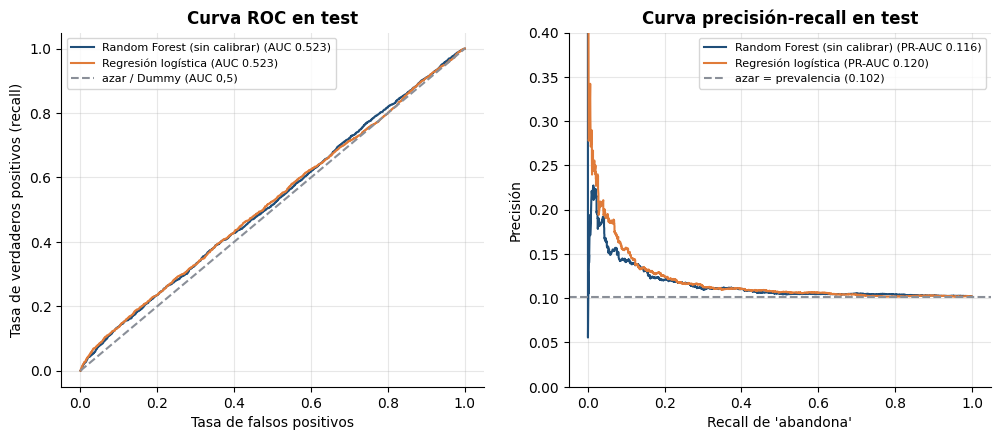

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
colores = {N_RF_RAW: plots.PALETA["principal"], N_LR: plots.PALETA["enfasis"]}
for n, p in ((N_RF_RAW, p_rf_te), (N_LR, p_lr_te)):
    fpr, tpr, _ = roc_curve(yte, p)
    axs[0].plot(fpr, tpr, color=colores[n], label=f"{n} (AUC {MET[n]['roc_auc']['valor']:.3f})")
    pr, rc, _ = precision_recall_curve(yte, p)
    axs[1].plot(rc, pr, color=colores[n], label=f"{n} (PR-AUC {MET[n]['pr_auc']['valor']:.3f})")
axs[0].plot([0, 1], [0, 1], color=plots.PALETA["neutro"], ls="--", label="azar / Dummy (AUC 0,5)")
axs[0].set_xlabel("Tasa de falsos positivos")
axs[0].set_ylabel("Tasa de verdaderos positivos (recall)")
axs[0].set_title("Curva ROC en test")
axs[0].legend(fontsize=8)
axs[1].axhline(PI_TE, color=plots.PALETA["neutro"], ls="--", label=f"azar = prevalencia ({PI_TE:.3f})")
axs[1].set_xlabel("Recall de 'abandona'")
axs[1].set_ylabel("Precisión")
axs[1].set_ylim(0, 0.4)
axs[1].set_title("Curva precisión-recall en test")
axs[1].legend(fontsize=8)
plots.save_fig(fig, "03_curvas_roc_pr")
plt.show()

**Conclusión técnica (test, n = 20.192 interacciones, 2.000 usuarios, IC por usuario):** el RF
alcanza ROC-AUC **0,5227 [0,5095; 0,5361]** y PR-AUC **0,1156 [0,1087; 0,1248]** frente a una
prevalencia de 0,1018. El IC del AUC **excluye 0,5** (coherente con p = 0,020 de la
permutación), pero la mejora sobre el Dummy es de +0,023 [0,010; 0,036] de AUC y +0,014
[0,008; 0,021] de PR-AUC: significativa y de magnitud mínima. El RF **no supera** a la regresión
logística (ΔAUC = −0,0001 [−0,0105; 0,0115]; ΔPR-AUC = −0,0043 [−0,0101; 0,0005]): sin
diferencia significativa, y no se justifica el modelo complejo. El Brier del RF calibrado
(0,0914 [0,0882; 0,0950]) es indistinguible del de la referencia (0,0915). Al umbral por costo
(0,25) el RF marca el 0,4 % de las interacciones con una precisión de 0,176 (por debajo del 0,25
que exige 3:1), F1 = 0,0122 [0,0057; 0,0189], recall = 0,0063 [0,0030; 0,0098]: prácticamente no
detecta abandonos; su costo en test (0,3066) no mejora al de no marcar a nadie (0,3055). Al umbral de F2, recall =
1 con precisión 0,102 = prevalencia y F1 = 0,185 (el F1 de "marcar a todos") a un costo de 0,898.

**Implicación de negocio:** hay una señal real pero diminuta; el modelo no identifica a los
usuarios que abandonarán mejor de lo que lo haría un criterio simple, y no debe usarse para
decidir a quién contactar.

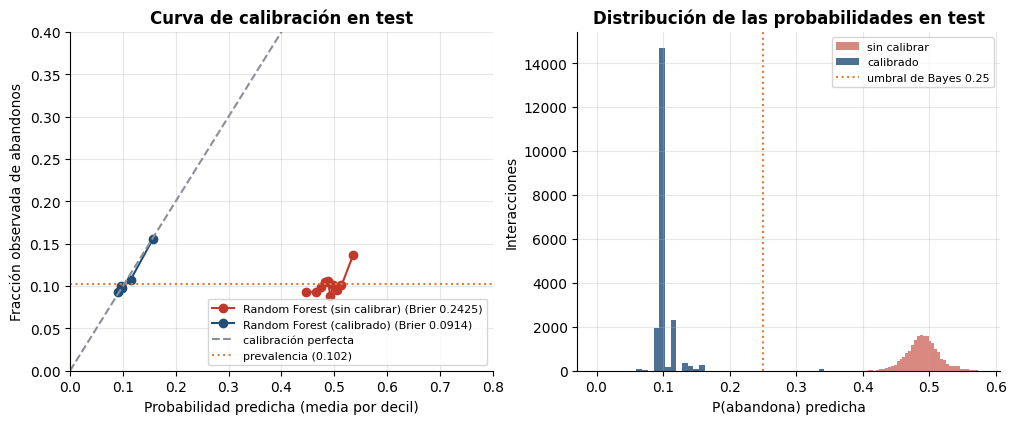

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
for n, p in ((N_RF_RAW, p_rf_te), (N_RF, p_cal_te)):
    frac, media = calibration_curve(yte, p, n_bins=10, strategy="quantile")
    axs[0].plot(media, frac, "o-", label=f"{n} (Brier {MET[n]['brier']['valor']:.4f})",
                color=plots.PALETA["referencia"] if "sin" in n else plots.PALETA["principal"])
axs[0].plot([0, 1], [0, 1], color=plots.PALETA["neutro"], ls="--", label="calibración perfecta")
axs[0].axhline(PI_TE, color=plots.PALETA["enfasis"], ls=":", label=f"prevalencia ({PI_TE:.3f})")
axs[0].set_xlim(0, 0.8)
axs[0].set_ylim(0, 0.4)
axs[0].set_xlabel("Probabilidad predicha (media por decil)")
axs[0].set_ylabel("Fracción observada de abandonos")
axs[0].set_title("Curva de calibración en test")
axs[0].legend(fontsize=8)
axs[1].hist(p_rf_te, bins=40, alpha=0.6, color=plots.PALETA["referencia"], label="sin calibrar")
axs[1].hist(p_cal_te, bins=40, alpha=0.8, color=plots.PALETA["principal"], label="calibrado")
axs[1].axvline(BAYES, color=plots.PALETA["enfasis"], ls=":", label=f"umbral de Bayes {BAYES:.2f}")
axs[1].set_xlabel("P(abandona) predicha")
axs[1].set_ylabel("Interacciones")
axs[1].set_title("Distribución de las probabilidades en test")
axs[1].legend(fontsize=8)
plots.save_fig(fig, "03_calibracion")
plt.show()

**Conclusión técnica:** sin calibrar, las probabilidades del RF con `class_weight` están muy por
encima de la frecuencia real (media 0,49 frente a 0,10; Brier 0,2425 [0,2421; 0,2430] frente a
0,0915 de la referencia). Tras la calibración isotónica (elegida en validación y aplicada al
test sin reajuste) la curva se pega a la diagonal en un rango muy estrecho de probabilidades
alrededor de π y el Brier (0,0914) iguala a la referencia: **calibrado no equivale a
discriminante**; el histograma muestra que casi toda la masa está en 0,05–0,15.

**Implicación de negocio:** las probabilidades del modelo serían fiables como frecuencias, pero
esas frecuencias son prácticamente "10 % para todos".

## 7. Importancia de variables (impurity y permutation)

**Qué:** dos medidas con sesgos distintos. *Impurity* (disminución media de impureza en el
train): barata, pero **sesgada hacia variables continuas o de alta cardinalidad** (más puntos
de corte posibles) y calculada sobre los datos de ajuste, de modo que un modelo que memoriza
ruido también reparte importancia. *Permutation* (sobre **validación**, `N_REP_IMP`
repeticiones, caída media del ROC-AUC al barajar la columna): mide la contribución al
desempeño fuera de muestra; con colinealidad puede subestimar variables correlacionadas.
Con señal casi nula, **las importancias son en su mayor parte ruido**: la permutación debe quedar ≈ 0.

Top 8 por impurity (train):
            variable  impurity
tasa_abandono_titulo    0.1448
             Runtime    0.1086
         No_of_Votes    0.1079
       Released_Year    0.0964
          Meta_score    0.0807
         IMDB_Rating    0.0531
      ag_youth_Drama    0.0187
             g_Crime    0.0184

Top 8 por permutation (validación; caída media de ROC-AUC ± sd):
            variable  media     sd
      ag_youth_Drama 0.0055 0.0013
             g_Crime 0.0025 0.0014
tasa_abandono_titulo 0.0018 0.0032
   ag_seniors_Family 0.0013 0.0006
         g_Adventure 0.0010 0.0005
        edad_seniors 0.0010 0.0003
          edad_youth 0.0010 0.0006
  ag_youth_Adventure 0.0009 0.0002

Variables con media - 2·sd > 0 en permutation: 16 de 93 (la sd mide solo la variabilidad del barajado, no la incertidumbre muestral: ranking descriptivo)
Importancia por permutation: máx 0.00555 | mediana -0.00001


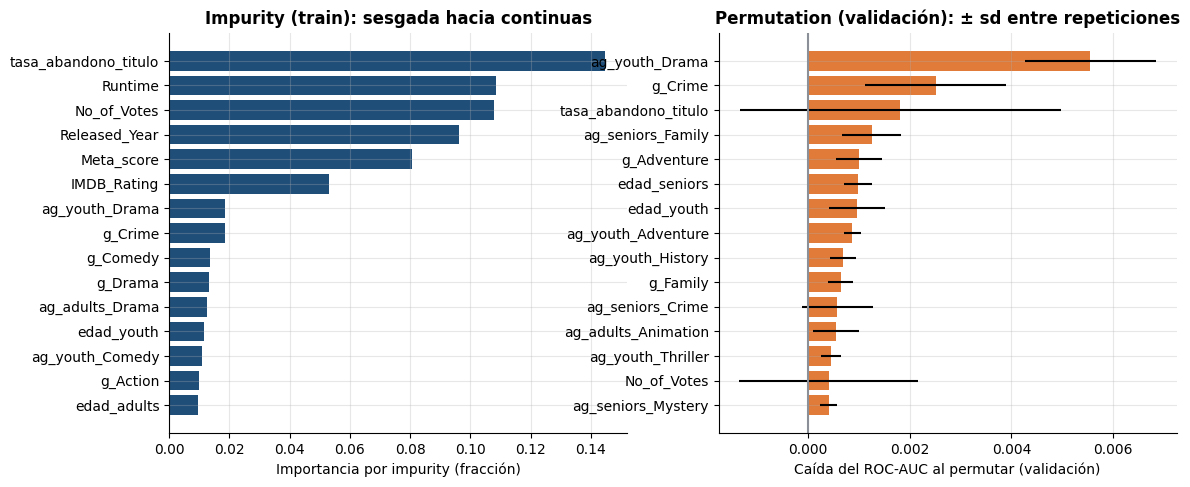

In [14]:
def importancia_permutacion(pipe, df, y, n_rep, seed, max_filas=None, cols=None):
    """Importancia por permutación (caída de ROC-AUC) sobre la matriz ya transformada por el prep."""
    cols = COLS if cols is None else cols
    if max_filas is not None and len(df) > max_filas:
        sub = np.random.default_rng(seed).choice(len(df), size=max_filas, replace=False)
        df, y = df.iloc[sub], np.asarray(y)[sub]
    Xt = pipe.named_steps["prep"].transform(df[cols])
    r = permutation_importance(pipe.named_steps["clf"], Xt, y, scoring="roc_auc",
                               n_repeats=n_rep, random_state=seed, n_jobs=1)
    return pd.DataFrame({"variable": Xt.columns, "media": r.importances_mean,
                         "sd": r.importances_std}).sort_values("media", ascending=False)


with seccion("7_importancias"):
    nombres = rf_final.named_steps["prep"].get_feature_names_out()
    imp_imp = pd.DataFrame({"variable": nombres,
                            "impurity": rf_final.named_steps["clf"].feature_importances_}
                           ).sort_values("impurity", ascending=False)
    imp_perm = importancia_permutacion(rf_final, va, yva, N_REP_IMP, SEED)

print("Top 8 por impurity (train):")
print(imp_imp.head(8).to_string(index=False))
print("\nTop 8 por permutation (validación; caída media de ROC-AUC ± sd):")
print(imp_perm.head(8).to_string(index=False))
n_sig = int((imp_perm["media"] - 2 * imp_perm["sd"] > 0).sum())
print(f"\nVariables con media - 2·sd > 0 en permutation: {n_sig} de {len(imp_perm)} "
      "(la sd mide solo la variabilidad del barajado, no la incertidumbre muestral: ranking descriptivo)")
print(f"Importancia por permutation: máx {imp_perm['media'].max():.5f} | "
      f"mediana {imp_perm['media'].median():.5f}")

fig, axs = plt.subplots(1, 2, figsize=(13, 5.2))
t = imp_imp.head(15).iloc[::-1]
axs[0].barh(t["variable"], t["impurity"], color=plots.PALETA["principal"])
axs[0].set_xlabel("Importancia por impurity (fracción)")
axs[0].set_title("Impurity (train): sesgada hacia continuas")
t = imp_perm.head(15).iloc[::-1]
axs[1].barh(t["variable"], t["media"], xerr=t["sd"], color=plots.PALETA["enfasis"])
axs[1].axvline(0, color=plots.PALETA["neutro"])
axs[1].set_xlabel("Caída del ROC-AUC al permutar (validación)")
axs[1].set_title("Permutation (validación): ± sd entre repeticiones")
plots.save_fig(fig, "03_importancia_variables")
plt.show()

**Conclusión técnica:** por impurity encabezan la lista las variables continuas o de alta
cardinalidad (`tasa_abandono_titulo` 0,145, `Runtime`, `No_of_Votes`, `Released_Year`,
`Meta_score`, `IMDB_Rating`): es el sesgo esperado de la medida (más puntos de corte posibles) y,
calculada sobre train, también reparte importancia sobre ruido memorizado. Por permutation, la
mayor caída de ROC-AUC es de 0,0055 (`ag_youth_Drama`), seguida de `g_Crime` (0,0025) y de la
tasa por título (0,0018 ± 0,0032); el resto ≈ 0 (mediana −0,00001). Es consistente con el rastro de
señal del grupo de edad *youth* (abandona un 10,8 % frente a 9,8–10,1 % en los demás grupos),
pero ninguna variable aporta más de ≈ 0,5 pp de AUC. Las dos medidas no coinciden, y la
dispersión mostrada (sd entre repeticiones del barajado) no es una medida de incertidumbre
muestral, de modo que no se contrastan hipótesis con ella: es un ranking descriptivo. Es la
contraparte de la sección 10, donde con señal sembrada las importancias sí apuntan con claridad a
las variables correctas.

**Implicación de negocio:** no hay un "motor de abandono" identificable en duración, año,
valoraciones o género; solo un leve efecto del grupo de edad joven, que no basta para actuar.

## 8. Análisis cualitativo de errores

**Qué:** sin umbral operativo útil (no se marca a nadie), los errores se ordenan por
**confianza**: los falsos negativos más confiados son los abandonos reales con menor
probabilidad predicha; los falsos positivos más confiados, las visualizaciones completas con
mayor probabilidad predicha. Se busca si comparten algún patrón (edad, género, duración,
título) y se tabula la tasa observada de abandono por decil de puntuación (un ranking útil
tendría una tasa creciente con el decil).

In [15]:
N_EJ = 5 if FAST else 10
err = te.assign(p=p_cal_te, p_raw=p_rf_te)
cols_ej = ["User_ID", "Series_Title", "Age_Group", "Genre", "Runtime", "Released_Year", "p"]
fn_top = err[err[ft.COL_Y] == 1].sort_values("p_raw").head(N_EJ)[cols_ej]
fp_top = err[err[ft.COL_Y] == 0].sort_values("p_raw", ascending=False).head(N_EJ)[cols_ej]
print(f"Falsos NEGATIVOS más confiados (abandonó; el modelo daba menor probabilidad), top {N_EJ}:")
print(fn_top.to_string(index=False))
print(f"\nFalsos POSITIVOS más confiados (vio completo; el modelo daba mayor probabilidad), top {N_EJ}:")
print(fp_top.to_string(index=False))

top_fp = err[err[ft.COL_Y] == 0].sort_values("p_raw", ascending=False).head(500)
top_fn = err[err[ft.COL_Y] == 1].sort_values("p_raw").head(500)
base = err
comp = pd.DataFrame({
    "población": [base["Runtime"].mean(), base["Age_Group"].eq("youth").mean(),
                  base[ft.COL_TITULO].nunique()],
    "500 FP más confiados": [top_fp["Runtime"].mean(), top_fp["Age_Group"].eq("youth").mean(),
                             top_fp[ft.COL_TITULO].nunique()],
    "500 FN más confiados": [top_fn["Runtime"].mean(), top_fn["Age_Group"].eq("youth").mean(),
                             top_fn[ft.COL_TITULO].nunique()],
}, index=["Runtime medio (min)", "fracción youth", "títulos distintos"])
print("\nPerfil de los 500 errores más confiados frente a la población de test:")
print(comp.to_string())

err["decil"] = pd.qcut(err["p_raw"].rank(method="first"), 10, labels=False) + 1
dec = err.groupby("decil").agg(n=("p", "size"), p_media=("p_raw", "mean"),
                               tasa_abandono=(ft.COL_Y, "mean"))
print("\nTasa observada de abandono por decil de puntuación del RF (1 = más bajo):")
print(dec.to_string())
print(f"Cociente decil 10 / decil 1: {dec['tasa_abandono'].iloc[-1] / dec['tasa_abandono'].iloc[0]:.2f} "
      f"(un modelo útil mostraría un cociente claramente > 1 y una tasa creciente)")

Falsos NEGATIVOS más confiados (abandonó; el modelo daba menor probabilidad), top 10:
 User_ID                    Series_Title Age_Group                    Genre  Runtime  Released_Year      p
    1489                          Freaks    adults            Drama, Horror       64           1932 0.0600
    4933                    Interstellar    adults Adventure, Drama, Sci-Fi      169           2014 0.0600
    2486                  Doctor Zhivago    adults      Drama, Romance, War      197           1965 0.0600
    6755  All Quiet on the Western Front    adults               Drama, War      152           1930 0.0600
     767              Gone with the Wind     youth  Drama, History, Romance      238           1939 0.0600
    8675                English Vinglish   seniors    Comedy, Drama, Family      134           2012 0.0714
    6350            Inglourious Basterds    adults    Adventure, Drama, War      153           2009 0.0714
    7268                   La dolce vita    adults        

**Conclusión técnica:** los falsos positivos más confiados se concentran: el 83 % de los 500
primeros son usuarios *youth* (frente al 33 % de la población de test) y solo 86 títulos
distintos (de 999), con repeticiones de la misma combinación (p. ej. *American History X* en
usuarios jóvenes, con probabilidad calibrada 0,34). Es el reflejo directo de lo único que el
modelo ha aprendido (`ag_youth_Drama`, tasa por título), no un patrón de negocio hallado. Los
falsos negativos más confiados son abandonos de usuarios adultos/seniors (solo el 25 % *youth*)
en películas algo más largas (128 min frente a 123), con probabilidades 0,06–0,09: el
modelo los trata como "muy poco probables" y se equivoca porque la tasa base del 10 % se
reparte casi uniformemente. La tasa de abandono por decil es plana entre los deciles 1–9
(8,9–10,6 %, dentro del ruido de muestreo de ≈ ±0,7 pp por decil de ≈ 2.000 filas) y solo el
decil 10 destaca (13,6 %, cociente 1,47 frente al decil 1): un lift real pero que sigue
por debajo del 25 % que justificaría actuar con costos 3:1.

**Implicación de negocio:** el modelo solo "ve" al joven que ve ciertos dramas; ese efecto es
demasiado pequeño para focalizar acciones y no explica los abandonos de los demás usuarios.

## 9. Costo operativo

**Qué:** el estándar exige reportar tiempo de entrenamiento, latencia por predicción y tamaño.
Latencia individual: `predict_proba` de **una** fila con `n_jobs = 1` (el caso de servir una
petición; el paralelismo del bosque penaliza las peticiones sueltas). Latencia por lotes: todo
el test con `n_jobs` completo. Tamaño: serialización de `joblib` en memoria (sin escribir archivos).

In [16]:
with seccion("9_costo_operativo"):
    rf_1 = clone(rf_final).set_params(clf__n_jobs=1).fit(tr[COLS], ytr)
    filas_1 = [te.iloc[[i]][COLS] for i in range(200)]
    rf_1.predict_proba(filas_1[0])  # calentamiento
    lat = []
    for f in filas_1:
        t0 = time.perf_counter()
        rf_1.predict_proba(f)
        lat.append(time.perf_counter() - t0)
    t0 = time.perf_counter()
    rf_final.predict_proba(te[COLS])
    lat_lote = (time.perf_counter() - t0) / len(te)
    buf = io.BytesIO()
    joblib.dump(rf_final, buf)
    tam_mb = buf.getbuffer().nbytes / 1e6

COSTO = {
    "tiempo_busqueda_s": TIEMPOS["3_busqueda_rf"],
    "tiempo_ajuste_final_s": round(T_REFIT, 2),
    "latencia_individual_ms_mediana": round(float(np.median(lat)) * 1e3, 2),
    "latencia_individual_ms_p95": round(float(np.quantile(lat, 0.95)) * 1e3, 2),
    "latencia_lote_ms_por_fila": round(lat_lote * 1e3, 4),
    "tamano_modelo_mb": round(tam_mb, 1),
    "n_arboles": int(MEJORES["n_estimators"]), "nucleos": N_JOBS,
}
print(pd.Series(COSTO).to_string())

tiempo_busqueda_s                 82.9000
tiempo_ajuste_final_s              1.5000
latencia_individual_ms_mediana     9.3400
latencia_individual_ms_p95        10.6800
latencia_lote_ms_por_fila          0.0037
tamano_modelo_mb                   2.3000
n_arboles                        200.0000
nucleos                           16.0000


**Conclusión técnica:** el bosque elegido (200 árboles) se ajusta en ≈ 2 s, la búsqueda de 60
ajustes con CV cuesta ≈ 80-95 s, la latencia es de ≈ 9 ms por predicción individual (dominada por
el costo fijo del `ColumnTransformer` y de la API de scikit-learn; con `n_jobs = 1`) y de
≈ 0,004 ms por fila en lote, y el modelo serializado pesa ≈ 2,3 MB. El costo operativo no es un
obstáculo; lo es la falta de señal.

**Implicación de negocio:** desplegarlo costaría poco, pero no aportaría valor: el costo no es
el criterio de decisión aquí.

## 10. Validación con señal sembrada: ¿el método detecta señal cuando existe?

**Qué:** un AUC ≈ 0,5 admite dos lecturas: *no hay señal* o *el método no es capaz de
detectarla*. Para separarlas se sustituye la etiqueta real por una **sintética con probabilidad
conocida** sobre la **misma tabla de features** y se pasa por **exactamente el mismo
pipeline** (mismos hiperparámetros elegidos en la sección 3, sin repetir la búsqueda; misma
partición por usuario; mismo target encoding; una evaluación en test por conjunto sintético).

**Modelo generativo** (`syn.generar_abandono_sembrado`, semilla fija):
`logit(p) = b0 + k · (0,8 · z(Runtime) + 0,9 · 1[youth × Action] − 0,9 · 1[seniors × Comedy])`,
con `b0` calibrado para una prevalencia de ≈ 10,25 % y `k` la **intensidad** (0 = sin señal,
0,5 = media, 1,0 = alta). Referencia de techo: el **AUC "oráculo"** (el de la probabilidad
verdadera como puntuación), el máximo alcanzable por cualquier modelo. Con `k = 0` el
procedimiento debe reproducir el ≈ 0,5 de los datos reales.

**Limitación:** es un caso favorable, la señal usa variables que el modelo ya recibe y es
aditiva en el logit; en la vida real la señal puede estar en variables ausentes (justo lo que
sugiere el caso real).

Dosis-respuesta en test (bootstrap por usuario):
 intensidad  prevalencia        AUC RF [IC 95 %]   AUC oráculo [IC 95 %]  PR-AUC RF
     0.0000       0.1017 0.5021 [0.4893, 0.5151] 0.5000 [0.5000, 0.5000]     0.1033
     0.5000       0.1022 0.6391 [0.6264, 0.6506] 0.6464 [0.6340, 0.6582]     0.1754
     1.0000       0.1026 0.7470 [0.7355, 0.7583] 0.7532 [0.7423, 0.7642]     0.3033

Intensidad 0.5: posiciones de las variables sembradas en permutation (1 = la más importante): {'Runtime': 1, 'ag_youth_Action': 5, 'ag_seniors_Comedy': 3}
            variable  media     sd
             Runtime 0.0459 0.0047
tasa_abandono_titulo 0.0040 0.0010
   ag_seniors_Comedy 0.0039 0.0009
            g_Comedy 0.0018 0.0004
     ag_youth_Action 0.0014 0.0009
         No_of_Votes 0.0006 0.0005

Intensidad 1.0: posiciones de las variables sembradas en permutation (1 = la más importante): {'Runtime': 1, 'ag_youth_Action': 4, 'ag_seniors_Comedy': 3}
            variable  media     sd
             Runtime 0.

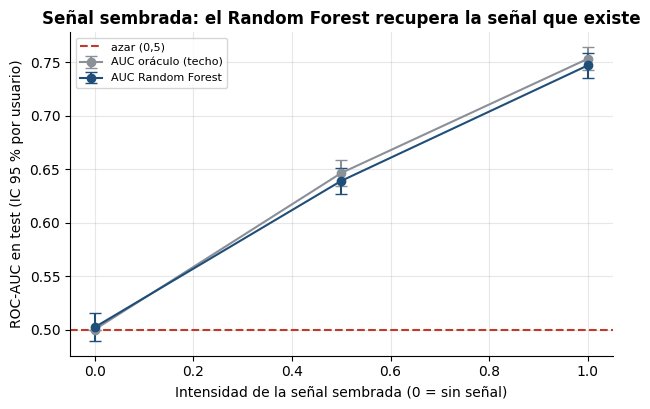

In [17]:
SEMBRADAS = ["Runtime", "ag_youth_Action", "ag_seniors_Comedy"]
PI_REAL = float(tabla[ft.COL_Y].mean())
res_s = {}
with seccion("10_senal_sembrada"):
    for k in INTENSIDADES:
        y_s, p_s = syn.generar_abandono_sembrado(tabla, k, prevalencia=PI_REAL, seed=SEED)
        tabla_s = tabla.assign(**{ft.COL_Y: y_s})
        tr_s, va_s, te_s = (tabla_s.iloc[idx[n]].reset_index(drop=True)
                            for n in ("train", "validacion", "test"))
        pipe_s = clone(rf_final).fit(tr_s[COLS], tr_s[ft.COL_Y].to_numpy())
        p_te_s = proba(pipe_s, te_s)
        p_orac = p_s[idx["test"]]
        b = ev.bootstrap_por_grupos(te_s[ft.COL_Y].to_numpy(), {"RF": p_te_s, "Oráculo": p_orac},
                                    te_s[ft.COL_USUARIO].to_numpy(), referencia="Oráculo",
                                    n_boot=N_BOOT, seed=SEED)
        imp_s = None
        if k > 0:
            imp_s = importancia_permutacion(pipe_s, va_s, va_s[ft.COL_Y].to_numpy(),
                                            max(2, N_REP_IMP - 2), SEED,
                                            max_filas=8000 if FAST else 12000)
        res_s[k] = {"prevalencia": float(y_s.mean()), "rf": b["modelos"]["RF"]["roc_auc"],
                    "oraculo": b["modelos"]["Oráculo"]["roc_auc"],
                    "pr_rf": b["modelos"]["RF"]["pr_auc"],
                    "dif_rf_oraculo": b["diferencias"]["RF"]["roc_auc"], "imp": imp_s}

filas = [{"intensidad": k, "prevalencia": r["prevalencia"], "AUC RF [IC 95 %]": fmt(r["rf"]),
          "AUC oráculo [IC 95 %]": fmt(r["oraculo"]), "PR-AUC RF": r["pr_rf"]["valor"]}
         for k, r in res_s.items()]
print("Dosis-respuesta en test (bootstrap por usuario):")
print(pd.DataFrame(filas).to_string(index=False))
for k, r in res_s.items():
    if r["imp"] is None:
        continue
    pos = {v: int(np.flatnonzero(r["imp"]["variable"].to_numpy() == v)[0]) + 1 for v in SEMBRADAS}
    print(f"\nIntensidad {k}: posiciones de las variables sembradas en permutation (1 = la más importante): {pos}")
    print(r["imp"].head(6).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4.2))
xs = list(res_s)
for clave, etq, col in (("oraculo", "AUC oráculo (techo)", "neutro"), ("rf", "AUC Random Forest", "principal")):
    v = [res_s[k][clave]["valor"] for k in xs]
    lo = [res_s[k][clave]["ic95"][0] for k in xs]
    hi = [res_s[k][clave]["ic95"][1] for k in xs]
    ax.errorbar(xs, v, yerr=[np.array(v) - lo, np.array(hi) - v], marker="o", capsize=4,
                label=etq, color=plots.PALETA[col])
ax.axhline(0.5, color=plots.PALETA["referencia"], ls="--", label="azar (0,5)")
ax.set_xlabel("Intensidad de la señal sembrada (0 = sin señal)")
ax.set_ylabel("ROC-AUC en test (IC 95 % por usuario)")
ax.set_title("Señal sembrada: el Random Forest recupera la señal que existe")
ax.legend(fontsize=8)
plots.save_fig(fig, "03_senal_sembrada")
plt.show()

**Conclusión técnica:** con intensidad 0 el pipeline reproduce el azar (ROC-AUC 0,5021 [0,4893;
0,5151], IC que contiene 0,5): el método no inventa señal. Con intensidad 0,5 el RF alcanza
0,639 [0,626; 0,651] (oráculo 0,646) y con 1,0, 0,747 [0,736; 0,758] (oráculo 0,753): el IC queda muy
por encima de 0,5 y a solo ≈ 0,006–0,007 del techo (esa diferencia, aunque pequeña, es
significativa: ΔAUC −0,006 [−0,009; −0,003] con intensidad 1; el RF estima con ruido y no ve la
probabilidad verdadera sino etiquetas Bernoulli). Las importancias por permutación sitúan
`Runtime` en el puesto 1 con ambas intensidades (caída de AUC de 0,046 y 0,067),
`ag_seniors_Comedy` en el 3 (ambas) y `ag_youth_Action` en el 5 (0,5) y el 4 (1,0); en el 2.º puesto
queda `tasa_abandono_titulo`, que actúa como *proxy* de la duración y del género del título
(la señal sembrada es una propiedad del título). Por tanto el procedimiento (partición por usuario +
target encoding out-of-fold + RF + IC por usuario + permutation) **detecta señal cuando existe y
la atribuye a las variables correctas**. Contraste: en los datos reales el RF alcanza 0,523, muy
lejos del 0,64–0,75 que produce una señal sembrada moderada. Limitación: la señal sembrada es el
caso favorable (variables ya presentes y efecto aditivo en el logit).

**Implicación de negocio:** el resultado casi nulo de los datos reales no es un fallo de la
metodología sino una propiedad de los datos: hay que recoger otros.

## 11. Techo de señal e ingeniería de características

**Qué:** responder a "¿cuánto se podría predecir con *estas* variables y llega el Random
Forest a ese techo?". Se (i) calcula el AUC de un **oráculo** (la regla que generó los datos),
(ii) se añaden features que representan bien esa estructura (género **exacto**, `n_generos` y
sus interacciones con la edad), (iii) se reentrena el RF con el mismo protocolo y se compara con
el oráculo y con el RF de T05, y (iv) se tabulan los **segmentos de riesgo** con su IC.

**Honestidad metodológica (leer antes de interpretar nada):**
1. **La regla no se descubrió a ciegas.** Se conoció inspeccionando `agent.py` (el simulador que
   generó `interacciones.csv`: compara la cadena **completa** de `Genre` con igualdad exacta) y se
   contrastó con los datos completos. Las features de esta sección se diseñaron *conociendo* ese
   proceso generador.
2. **El test ya se evaluó una vez (sección 6).** Esta segunda evaluación **no es una estimación
   limpia** de generalización: se presenta como **análisis de techo de señal**, no como selección
   de modelo. El modelo, el umbral y las métricas principales de T05 (`metricas`, `umbral` del
   JSON) **no se sustituyen**.
3. **Mitigación:** la búsqueda de hiperparámetros del nuevo RF se hace con CV agrupada por
   usuario **solo en train**, y se reporta también su AUC en **validación** (que no se usó para
   buscar). Todo lo aprendido de los datos (tasas por clave) se ajusta dentro del `Pipeline`,
   fuera de pliegue por usuario.

**Regla generadora (oráculo):** `youth × Genre` exactamente `Drama` u `Horror`; `seniors ×
Genre` exactamente `Comedy` o `Romance`; `adults` nunca se penaliza. Se estima el oráculo de tres
formas, todas con parámetros **solo de train**: (a) indicador binario del segmento; (b)
probabilidad por segmento (tasa del segmento en train y tasa base en train; ordena igual que
(a), así que su AUC coincide: se muestra por transparencia); (c) probabilidad por celda
(edad × género de la regla, tasa de train de cada celda).

**Por qué el techo es bajo:** el segmento es una fracción pequeña de las interacciones y eleva la
tasa solo de ≈ 10 % a ≈ 21 %. Para una puntuación que solo separa dos grupos,
`AUC = 0,5 + (TPR − FPR)/2`: si el segmento contiene una fracción pequeña de los abandonos
(TPR bajo) y de los no abandonos (FPR más bajo aún), la diferencia es mínima. Ningún modelo que
solo vea estas variables puede superar el AUC de la probabilidad verdadera.

In [18]:
with seccion("11_techo_oraculo"):
    GEN_REGLA = {"youth": ("Drama", "Horror"), "seniors": ("Comedy", "Romance")}

    def en_segmento(df: pd.DataFrame) -> np.ndarray:
        """True si (edad, género EXACTO) cae en la regla (youth: Drama/Horror; seniors: Comedy/Romance)."""
        m = np.zeros(len(df), dtype=bool)
        for edad, gens in GEN_REGLA.items():
            m |= ((df[ft.COL_EDAD] == edad) & df[ft.COL_GENERO_EXACTO].isin(gens)).to_numpy()
        return m

    seg_tr, seg_va, seg_te = en_segmento(tr), en_segmento(va), en_segmento(te)
    P_BASE_TR = float(ytr[~seg_tr].mean())
    P_SEG_TR = float(ytr[seg_tr].mean())
    # tasa por celda (edad, género de la regla), SOLO train; el resto recibe la tasa base
    celdas_tr = tr[seg_tr].groupby([ft.COL_EDAD, ft.COL_GENERO_EXACTO])[ft.COL_Y].mean()

    def oraculo(df: pd.DataFrame, seg: np.ndarray) -> dict[str, np.ndarray]:
        """Puntuaciones del oráculo con parámetros de train: binario, probabilidad y por celda."""
        celda = np.full(len(df), P_BASE_TR)
        for (edad, gen), tasa in celdas_tr.items():
            celda[((df[ft.COL_EDAD] == edad) & (df[ft.COL_GENERO_EXACTO] == gen)).to_numpy()] = tasa
        return {"Oráculo (binario)": seg.astype(float),
                "Oráculo (prob. train)": np.where(seg, P_SEG_TR, P_BASE_TR),
                "Oráculo (por celda)": celda}

    orac_te, orac_va = oraculo(te, seg_te), oraculo(va, seg_va)
    N_ORAC_B, N_ORAC_P, N_ORAC_C = list(orac_te)
    N_RF5 = "RF de T05"
    auc_orac_va = {k: float(roc_auc_score(yva, v)) for k, v in orac_va.items()}
    bo = ev.bootstrap_por_grupos(yte, {N_RF5: p_rf_te, **orac_te}, g_te, referencia=N_RF5,
                                 n_boot=N_BOOT, seed=SEED)

print(f"Segmento de la regla: {seg_tr.mean():.2%} de train ({seg_tr.sum():,} filas), "
      f"{seg_te.mean():.2%} de test ({seg_te.sum():,}).")
print(f"Tasa de abandono en train: segmento {P_SEG_TR:.4f} | resto {P_BASE_TR:.4f} | "
      f"cociente {P_SEG_TR / P_BASE_TR:.2f}")
print("Tasa por celda en train: " + " | ".join(f"{e}/{g} {t:.3f}" for (e, g), t in celdas_tr.items()))
print("\nROC-AUC en test (IC 95 % bootstrap por usuario) y diferencia pareada frente al RF de T05:")
filas = []
for n, m in bo["modelos"].items():
    d = bo["diferencias"].get(n)
    dtxt = "—" if d is None else (f"{d['roc_auc']['diferencia']:+.4f} "
                                  f"[{d['roc_auc']['ic95'][0]:+.4f}, {d['roc_auc']['ic95'][1]:+.4f}]")
    filas.append({"puntuación": n, "ROC-AUC [IC 95 %]": fmt(m["roc_auc"]), "PR-AUC": fmt(m["pr_auc"]),
                  "Δ AUC vs RF T05": dtxt})
print(pd.DataFrame(filas).to_string(index=False))
print("\nROC-AUC de los oráculos en validación: "
      + " | ".join(f"{k} {v:.4f}" for k, v in auc_orac_va.items()))

Segmento de la regla: 3.49% de train (2,098 filas), 3.27% de test (661).
Tasa de abandono en train: segmento 0.2054 | resto 0.0993 | cociente 2.07
Tasa por celda en train: seniors/Comedy 0.220 | youth/Drama 0.206 | youth/Horror 0.109

ROC-AUC en test (IC 95 % bootstrap por usuario) y diferencia pareada frente al RF de T05:
           puntuación       ROC-AUC [IC 95 %]                  PR-AUC            Δ AUC vs RF T05
            RF de T05 0.5227 [0.5095, 0.5361] 0.1156 [0.1087, 0.1248]                          —
    Oráculo (binario) 0.5178 [0.5128, 0.5236] 0.1083 [0.1032, 0.1141] -0.0049 [-0.0169, +0.0074]
Oráculo (prob. train) 0.5178 [0.5128, 0.5236] 0.1083 [0.1032, 0.1141] -0.0049 [-0.0169, +0.0074]
  Oráculo (por celda) 0.5178 [0.5128, 0.5236] 0.1083 [0.1033, 0.1141] -0.0049 [-0.0169, +0.0074]

ROC-AUC de los oráculos en validación: Oráculo (binario) 0.5202 | Oráculo (prob. train) 0.5202 | Oráculo (por celda) 0.5202


**Conclusión técnica (oráculo):** la regla exacta, con parámetros de train, alcanza ROC-AUC
**0,5178 [0,5128; 0,5236]** en test (0,5202 en validación) y PR-AUC 0,1083 [0,1032; 0,1141]
(azar 0,1018). El segmento es el 3,5 % de train y el 3,3 % de test, con una tasa de abandono de
20,5 % frente a 9,9 % fuera de él (cociente 2,07). Las tres variantes dan el mismo AUC: el
indicador, la probabilidad por segmento y la probabilidad por celda ordenan igual (Drama juvenil
0,206 y Comedy sénior 0,220 son casi idénticas, y Horror juvenil, 0,109 sobre ≈ 46 filas de
train, apenas pesa). **El techo con estas variables es ≈ 0,52.** El RF de T05 (0,5227 [0,5095;
0,5361]) **no se distingue del oráculo**: Δ(oráculo − RF T05) = −0,0049 [−0,0169; +0,0074]. Es
decir, ya antes de añadir features el RF estaba, dentro del error de muestreo, en el techo (la
señal le llegaba diluida vía `ag_youth_Drama`). El IC del oráculo es estrecho porque su puntuación
toma dos valores sin ruido de ajuste; no es comparable en anchura al del RF.

**Implicación de negocio:** aunque se conociera exactamente la regla de abandono, el AUC
individual no pasaría de ≈ 0,52: el problema no es el algoritmo sino la poca varianza explicable.

### 11.1 Features de género exacto y reentrenamiento del Random Forest

**Features** (`src/features.py`, con tests): `genero_exacto` (cadena completa de `Genre`),
`n_generos`, `genero_unico` (1 si `n_generos == 1`), `ng_<edad>` (`n_generos` × grupo de edad) y
la clave `edad_genero_exacto`. Las claves categóricas de alta cardinalidad (`genero_exacto`,
`edad_genero_exacto`) entran como **tasa de abandono por clave** con `TasaAbandonoTitulo`
generalizada: suavizada (m = 20), categorías no vistas → media global y, en `fit_transform`,
**codificación out-of-fold por usuario** dentro del `Pipeline` (un test unitario comprueba que con
etiquetas aleatorias la correlación con la etiqueta es ≈ 0, frente a la ingenua). **No se
codifica la regla a mano** (eso es el oráculo): se da la representación (edad × género exacto) y
el bosque aprende qué celdas importan. Se mantiene la tasa por título de T05.

**Protocolo idéntico al de la sección 3:** misma partición por usuario, `RandomizedSearchCV`
con `StratifiedGroupKFold(3)` agrupado por usuario sobre train y ROC-AUC como criterio, mismo
espacio de hiperparámetros pero **`n_iter` reducido a la mitad** para acotar el tiempo
(declarado: la búsqueda explora menos configuraciones que en T05).

In [19]:
COLS2 = ft.columnas_entrada_techo(GENEROS)
N_ITER2 = 3 if FAST else 10
pipe_rf2 = ft.crear_pipeline_techo(RandomForestClassifier(random_state=SEED, n_jobs=N_JOBS), GENEROS)
busqueda2 = RandomizedSearchCV(
    pipe_rf2, {f"clf__{k}": v for k, v in ESPACIO.items()}, n_iter=min(N_ITER2, N_COMBINACIONES),
    scoring=SCORING, cv=StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED),
    random_state=SEED, n_jobs=1, refit=True,
)
with seccion("11_busqueda_rf_nuevo"):
    busqueda2.fit(tr[COLS2], ytr, groups=tr[ft.COL_USUARIO])
rf2 = busqueda2.best_estimator_
MEJORES2 = {k.removeprefix("clf__"): v for k, v in busqueda2.best_params_.items()}
res2 = pd.DataFrame(busqueda2.cv_results_).sort_values("rank_test_score")
p_rf2_va = rf2.predict_proba(va[COLS2])[:, 1]
p_rf2_te = rf2.predict_proba(te[COLS2])[:, 1]
AUC2_VA = float(roc_auc_score(yva, p_rf2_va))
PR2_VA = float(average_precision_score(yva, p_rf2_va))
print(f"Búsqueda: {busqueda2.n_iter} configuraciones x {CV_FOLDS} folds (T05: {busqueda.n_iter}); "
      f"{TIEMPOS['11_busqueda_rf_nuevo']:.0f} s")
print(f"Elegidos: {MEJORES2}")
print(f"ROC-AUC CV (train) = {busqueda2.best_score_:.4f} | rango entre configuraciones "
      f"[{res2['mean_test_score'].min():.4f}, {res2['mean_test_score'].max():.4f}]  "
      f"(T05: {busqueda.best_score_:.4f})")
print(f"Validación: ROC-AUC {AUC2_VA:.4f} | PR-AUC {PR2_VA:.4f}  "
      f"(RF de T05: {AUC_VA['Random Forest']:.4f} | oráculo prob.: {auc_orac_va[N_ORAC_P]:.4f})")

with seccion("11_bootstrap_rf_nuevo"):
    N_RF2 = "RF con género exacto"
    bn = ev.bootstrap_por_grupos(yte, {N_RF2: p_rf2_te, N_RF5: p_rf_te, **orac_te}, g_te,
                                 referencia=N_RF5, n_boot=N_BOOT, seed=SEED)
    bn2 = ev.bootstrap_por_grupos(yte, {N_RF2: p_rf2_te, N_ORAC_P: orac_te[N_ORAC_P]}, g_te,
                                  referencia=N_ORAC_P, n_boot=N_BOOT, seed=SEED)
    bn3 = ev.bootstrap_por_grupos(yte, {N_RF2: p_rf2_te, N_ORAC_C: orac_te[N_ORAC_C]}, g_te,
                                  referencia=N_ORAC_C, n_boot=N_BOOT, seed=SEED)
M2 = bn["modelos"][N_RF2]
D_VS_T05 = bn["diferencias"][N_RF2]
D_VS_ORAC = bn2["diferencias"][N_RF2]
D_VS_ORAC_C = bn3["diferencias"][N_RF2]
print(f"\nTest (n = {len(yte):,}, {len(set(g_te)):,} usuarios): {N_RF2}  "
      f"ROC-AUC {fmt(M2['roc_auc'])} | PR-AUC {fmt(M2['pr_auc'])}  (azar PR-AUC = {PI_TE:.4f})")
print(f"  {N_RF5:21s}  ROC-AUC {fmt(bn['modelos'][N_RF5]['roc_auc'])} | "
      f"PR-AUC {fmt(bn['modelos'][N_RF5]['pr_auc'])}")
print(f"  {N_ORAC_P:21s}  ROC-AUC {fmt(bn2['modelos'][N_ORAC_P]['roc_auc'])} | "
      f"PR-AUC {fmt(bn2['modelos'][N_ORAC_P]['pr_auc'])}")
print("\nDiferencias pareadas (IC 95 % bootstrap por usuario):")
for nombre, d in (("RF nuevo − RF de T05", D_VS_T05),
                  (f"RF nuevo − {N_ORAC_P}", D_VS_ORAC),
                  (f"RF nuevo − {N_ORAC_C}", D_VS_ORAC_C)):
    print(f"  {nombre:36s} ROC-AUC {d['roc_auc']['diferencia']:+.4f} {np.round(d['roc_auc']['ic95'], 4)}"
          f" | PR-AUC {d['pr_auc']['diferencia']:+.4f} {np.round(d['pr_auc']['ic95'], 4)}")
ic_o = D_VS_ORAC["roc_auc"]["ic95"]
ALCANZA_TECHO = bool(ic_o[0] <= 0.0 <= ic_o[1])
falta = -D_VS_ORAC["roc_auc"]["diferencia"]
print(f"\n¿Alcanza el techo? IC 95 % de ΔAUC (RF nuevo − oráculo) = [{ic_o[0]:+.4f}, {ic_o[1]:+.4f}] -> "
      + ("contiene 0: SÍ" if ALCANZA_TECHO else f"NO contiene 0; faltan {falta:.4f} de AUC"))

Búsqueda: 10 configuraciones x 3 folds (T05: 20); 46 s
Elegidos: {'n_estimators': 100, 'min_samples_leaf': 100, 'max_samples': 0.6, 'max_features': 0.5, 'max_depth': 8, 'class_weight': 'balanced'}
ROC-AUC CV (train) = 0.5220 | rango entre configuraciones [0.5142, 0.5220]  (T05: 0.5205)
Validación: ROC-AUC 0.5173 | PR-AUC 0.1163  (RF de T05: 0.5208 | oráculo prob.: 0.5202)



Test (n = 20,192, 2,000 usuarios): RF con género exacto  ROC-AUC 0.5234 [0.5097, 0.5368] | PR-AUC 0.1176 [0.1105, 0.1266]  (azar PR-AUC = 0.1018)
  RF de T05              ROC-AUC 0.5227 [0.5095, 0.5361] | PR-AUC 0.1156 [0.1087, 0.1248]
  Oráculo (prob. train)  ROC-AUC 0.5178 [0.5128, 0.5236] | PR-AUC 0.1083 [0.1032, 0.1141]

Diferencias pareadas (IC 95 % bootstrap por usuario):
  RF nuevo − RF de T05                 ROC-AUC +0.0007 [-0.011   0.0129] | PR-AUC +0.0021 [-0.0023  0.0066]
  RF nuevo − Oráculo (prob. train)     ROC-AUC +0.0056 [-0.0075  0.0175] | PR-AUC +0.0094 [0.0054 0.0146]
  RF nuevo − Oráculo (por celda)       ROC-AUC +0.0056 [-0.0076  0.0174] | PR-AUC +0.0093 [0.0051 0.0145]

¿Alcanza el techo? IC 95 % de ΔAUC (RF nuevo − oráculo) = [-0.0075, +0.0175] -> contiene 0: SÍ


**Conclusión técnica (RF con género exacto):** en test alcanza ROC-AUC **0,5234 [0,5097; 0,5368]**
y PR-AUC 0,1176 [0,1105; 0,1266] (azar 0,1018); en validación, 0,5173 (RF de T05: 0,5208; oráculo:
0,5202), y en la CV de train, 0,5220 (T05: 0,5205; rango entre las 10 configuraciones
0,5142–0,5220, otra vez una búsqueda sin región destacada). Frente al RF de T05, la mejora es
**nula**: ΔAUC = +0,0007 [−0,0110; +0,0129], ΔPR-AUC = +0,0021 [−0,0023; +0,0066]. Frente al
oráculo, ΔAUC = +0,0056 [−0,0075; +0,0175] (el IC contiene 0: se **alcanza el techo** en el
sentido declarado, sin diferencia detectable) y ΔPR-AUC = +0,0094 [+0,0054; +0,0146], significativa
a favor del RF, lo que sugiere un poco de ordenación adicional dentro del segmento o en las
variables restantes (señal marginal que la regla de dos valores no modela). Que el IC contenga 0
no prueba equivalencia: con ±0,01 de ancho no se descarta una diferencia de ese orden. Lectura
honesta: las features nuevas **no mejoran el AUC**; el RF de T05 ya estaba en el techo y lo que
aportan es una representación que concentra la señal en una sola variable (sección 11.2). Se
recuerda que esta evaluación reutiliza el test ya visto y que las features se diseñaron conociendo
el generador: es un análisis de techo, no una nueva estimación de generalización.

**Implicación de negocio:** enriquecer las variables con el género exacto no hace al modelo más
útil; la información predictiva de este catálogo ya estaba agotada.

### 11.2 Importancias del RF con género exacto (impurity y permutation)

Mismas dos medidas y mismas cautelas que en la sección 7 (impurity sesgada hacia variables
continuas y calculada sobre train; permutation sobre **validación**, caída del ROC-AUC). La
pregunta es si las features de **género exacto × edad** quedan arriba. Como las tasas por clave
están correlacionadas con `ag_*`, `n_generos` y `genero_unico`, la permutación puede repartir o
subestimar su importancia (colinealidad).

Top 8 por impurity (train):
               variable  impurity
tasa_edad_genero_exacto    0.2456
   tasa_abandono_titulo    0.1273
     tasa_genero_exacto    0.0971
            No_of_Votes    0.0937
                Runtime    0.0879
          Released_Year    0.0672
             Meta_score    0.0530
            IMDB_Rating    0.0345

Top 8 por permutation (validación; caída media de ROC-AUC ± sd):
               variable  media     sd
tasa_edad_genero_exacto 0.0098 0.0024
                Runtime 0.0037 0.0040
   ag_seniors_Adventure 0.0011 0.0002
              ng_adults 0.0010 0.0003
     ag_seniors_Mystery 0.0006 0.0004
       ag_seniors_Drama 0.0005 0.0000
      ag_seniors_Family 0.0005 0.0003
                g_Crime 0.0005 0.0004

Posición de las features nuevas principales | permutation: {'tasa_edad_genero_exacto': 1, 'tasa_genero_exacto': 99, 'n_generos': 97} | impurity: {'tasa_edad_genero_exacto': 1, 'tasa_genero_exacto': 3, 'n_generos': 10}


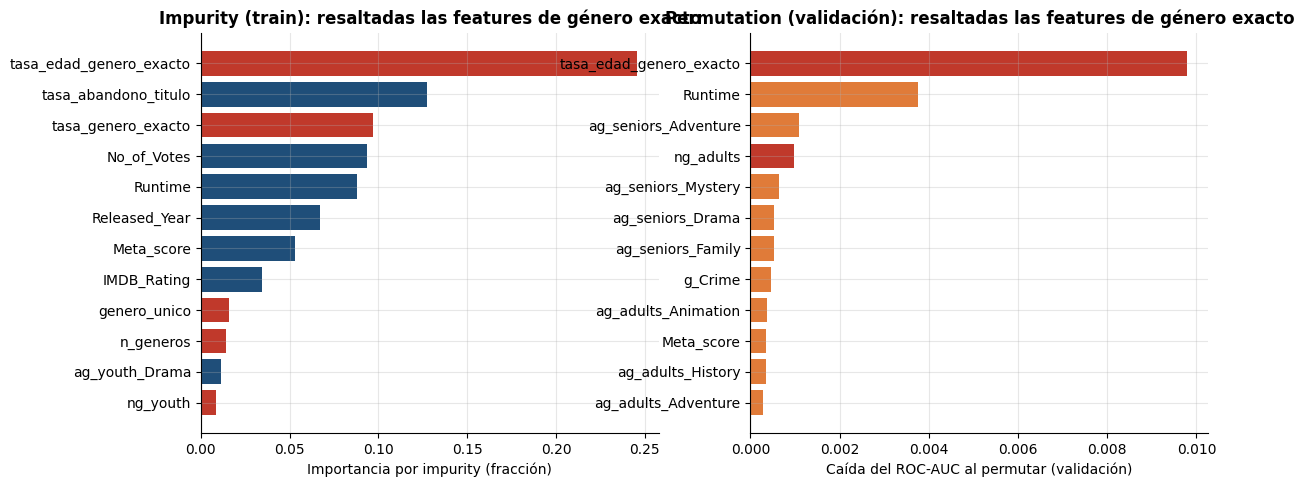

In [20]:
with seccion("11_importancias_rf_nuevo"):
    nombres2 = rf2.named_steps["prep"].get_feature_names_out()
    imp_imp2 = pd.DataFrame({"variable": nombres2, "impurity": rf2.named_steps["clf"].feature_importances_}
                            ).sort_values("impurity", ascending=False)
    imp_perm2 = importancia_permutacion(rf2, va, yva, N_REP_IMP, SEED, cols=COLS2)
print("Top 8 por impurity (train):")
print(imp_imp2.head(8).to_string(index=False))
print("\nTop 8 por permutation (validación; caída media de ROC-AUC ± sd):")
print(imp_perm2.head(8).to_string(index=False))
NUEVAS = {"tasa_edad_genero_exacto", "tasa_genero_exacto", "n_generos", "genero_unico",
          *[f"ng_{e}" for e in ft.EDADES]}
pos_perm = {v: int(np.flatnonzero(imp_perm2["variable"].to_numpy() == v)[0]) + 1
            for v in ("tasa_edad_genero_exacto", "tasa_genero_exacto", "n_generos")}
pos_imp = {v: int(np.flatnonzero(imp_imp2["variable"].to_numpy() == v)[0]) + 1 for v in pos_perm}
print(f"\nPosición de las features nuevas principales | permutation: {pos_perm} | impurity: {pos_imp}")

fig, axs = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, (df_i, col, tit, color) in zip(axs, ((imp_imp2, "impurity", "Impurity (train)", "principal"),
                                             (imp_perm2, "media", "Permutation (validación)", "enfasis"))):
    t = df_i.head(12).iloc[::-1]
    cols_b = [plots.PALETA["referencia"] if v in NUEVAS else plots.PALETA[color] for v in t["variable"]]
    ax.barh(t["variable"], t[col], color=cols_b)
    ax.set_title(f"{tit}: resaltadas las features de género exacto")
    ax.axvline(0, color=plots.PALETA["neutro"])
axs[0].set_xlabel("Importancia por impurity (fracción)")
axs[1].set_xlabel("Caída del ROC-AUC al permutar (validación)")
plots.save_fig(fig, "03_importancia_genero_exacto")
plt.show()

**Conclusión técnica (importancias):** `tasa_edad_genero_exacto` queda **primera** tanto por
impurity (0,2456, casi el doble que la siguiente, `tasa_abandono_titulo` 0,1273) como por
permutation (caída de AUC 0,0098 ± 0,0024 en validación; la siguiente, `Runtime`, 0,0037 ± 0,0040,
tiene una dispersión mayor que su media). `tasa_genero_exacto` es tercera por impurity pero 99.ª
por permutation, y `n_generos` 10.ª y 97.ª: son redundantes con la tasa edad × género
(colinealidad), y la permutación, que las evalúa de una en una, las ve prescindibles. El resto de
caídas es ≤ 0,0011. El modelo es así interpretable: la señal que usa es la celda (edad, género
exacto), no la duración ni los metadatos; la sd mide solo el barajado, no la incertidumbre
muestral, y la impurity favorece a las continuas (aun así, la tasa codificada supera a `Runtime`
y a `No_of_Votes`).

**Implicación de negocio:** la única variable con peso es «qué grupo de edad ve qué género
exacto», lo que apunta a una regla de catálogo y no a un modelo de usuario.

### 11.3 Segmentos de riesgo: edad × género exacto y número de géneros

**Qué:** tasa de abandono, `n` e IC 95 % de **Wilson** por segmento, calculadas sobre **train** y
**confirmadas en test** (el test no interviene en la selección de segmentos). Se consideran los
segmentos (edad × género exacto) de películas de **una sola etiqueta** con al menos `MIN_N` filas
en train, más las celdas de la regla aunque tengan pocas filas (Horror juvenil: n pequeño).
Se marca el segmento como de **riesgo** si el límite inferior del IC supera la tasa global de
train, y como de **riesgo tras Bonferroni** si lo hace con el IC de nivel `1 − 0,05/k` (k = nº
de segmentos).

**Cautela de multiplicidad:** con k segmentos y un IC individual al 95 %, se esperan ≈ 0,025·k
marcas por azar sin ninguna señal; por eso se informa también la versión corregida. Los
segmentos además se solapan (un mismo usuario o título cae en varios cortes).

In [21]:
from scipy.stats import norm  # noqa: E402

from src import stats as st  # noqa: E402

MIN_N = 100 if FAST else 150
SEG_REGLA = {("youth", "Drama"), ("youth", "Horror"), ("seniors", "Comedy"), ("seniors", "Romance")}


def tabla_segmentos(df: pd.DataFrame, claves: list[str], z: float = 1.96) -> pd.DataFrame:
    """n, abandonos, tasa e IC de Wilson (nivel dado por ``z``) por combinación de ``claves``."""
    t = df.groupby(claves)[ft.COL_Y].agg(n="size", eventos="sum")
    t["tasa"] = t["eventos"] / t["n"]
    t["ic_inf"], t["ic_sup"] = st.wilson_ci(t["eventos"], t["n"], z=z)
    return t


with seccion("11_segmentos"):
    unicos_tr, unicos_te = tr[tr["n_generos"] == 1], te[te["n_generos"] == 1]
    todos_tr = tabla_segmentos(unicos_tr, [ft.COL_EDAD, ft.COL_GENERO_EXACTO])
    mantener = [i for i, r in todos_tr.iterrows() if r["n"] >= MIN_N or i in SEG_REGLA]
    seg_tab = todos_tr.loc[mantener].copy()
    K_SEG = len(seg_tab)
    Z_BONF = float(norm.ppf(1 - 0.05 / (2 * K_SEG)))
    bonf = tabla_segmentos(unicos_tr, [ft.COL_EDAD, ft.COL_GENERO_EXACTO], z=Z_BONF).loc[mantener]
    te_tab = tabla_segmentos(unicos_te, [ft.COL_EDAD, ft.COL_GENERO_EXACTO]).reindex(mantener)
    seg_tab["riesgo"] = seg_tab["ic_inf"] > PI_TR
    seg_tab["riesgo_bonferroni"] = bonf["ic_inf"] > PI_TR
    seg_tab["en_regla"] = [i in SEG_REGLA for i in seg_tab.index]
    seg_tab["n_test"] = te_tab["n"]
    seg_tab["tasa_test"] = te_tab["tasa"]
    seg_tab["ic_test_inf"] = te_tab["ic_inf"]
    seg_tab["ic_test_sup"] = te_tab["ic_sup"]
    seg_tab = seg_tab.sort_values("tasa", ascending=False)

    ng_tr, ng_te = tabla_segmentos(tr, ["n_generos"]), tabla_segmentos(te, ["n_generos"])
    edad_ng_tr = tabla_segmentos(tr, [ft.COL_EDAD, "n_generos"])
    fuera_regla_1 = (~seg_tr) & (tr["n_generos"] == 1).to_numpy()

print(f"Tasa global de abandono en train: {PI_TR:.4f} | k = {K_SEG} segmentos (edad x género exacto, "
      f"una etiqueta, n >= {MIN_N} o celda de la regla) | z Bonferroni = {Z_BONF:.2f}")
cols_m = ["n", "tasa", "ic_inf", "ic_sup", "riesgo", "riesgo_bonferroni", "en_regla", "n_test", "tasa_test"]
print(seg_tab[cols_m].rename(columns={"n": "n_train", "tasa": "tasa_train", "ic_inf": "ic_inf_tr",
                                      "ic_sup": "ic_sup_tr"}).head(12).to_string())
print(f"... (12 de {K_SEG} segmentos, por tasa). Marcados de riesgo (IC > global): "
      f"{int(seg_tab['riesgo'].sum())} | tras Bonferroni: {int(seg_tab['riesgo_bonferroni'].sum())} | "
      f"esperados por azar sin señal ≈ {0.025 * K_SEG:.1f}")
print("Segmentos de riesgo: " + ", ".join(f"{e}/{g}" for (e, g) in seg_tab.index[seg_tab["riesgo"]]))
print("\nPor número de géneros (todas las interacciones):")
print(ng_tr.join(ng_te, lsuffix="_train", rsuffix="_test")[
    ["n_train", "tasa_train", "ic_inf_train", "ic_sup_train", "n_test", "tasa_test"]].to_string())
print("\nPor edad x número de géneros (train):")
print(edad_ng_tr[["n", "tasa", "ic_inf", "ic_sup"]].to_string())
print(f"\nUna sola etiqueta y fuera de la regla: tasa {ytr[fuera_regla_1].mean():.4f} "
      f"(n = {fuera_regla_1.sum():,}) frente a {P_SEG_TR:.4f} en el segmento de la regla.")

Tasa global de abandono en train: 0.1030 | k = 7 segmentos (edad x género exacto, una etiqueta, n >= 150 o celda de la regla) | z Bonferroni = 2.69
                         n_train  tasa_train  ic_inf_tr  ic_sup_tr  riesgo  riesgo_bonferroni  en_regla  n_test  tasa_test
Age_Group genero_exacto                                                                                                   
seniors   Comedy             286      0.2203     0.1761     0.2718    True               True      True     101     0.1980
youth     Drama             1766      0.2055     0.1874     0.2250    True               True      True     544     0.2040
adults    Comedy             285      0.1228     0.0896     0.1660   False              False     False      87     0.0460
youth     Horror              46      0.1087     0.0473     0.2304   False              False      True      16     0.1250
seniors   Drama             1657      0.0929     0.0799     0.1079   False              False     False     591   

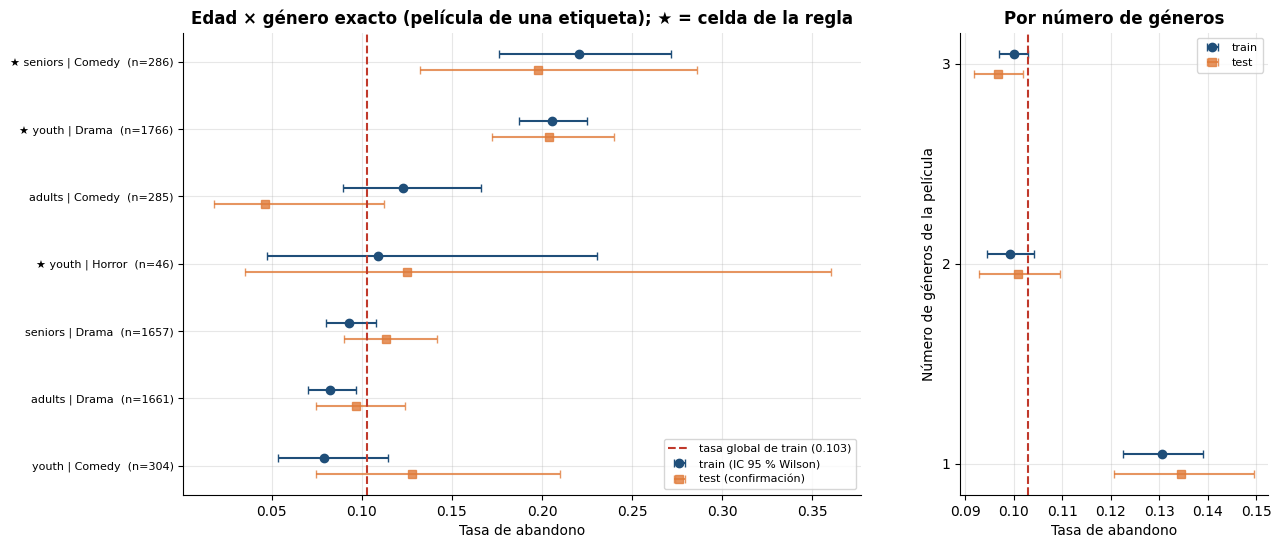

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axs[0]
t = seg_tab.iloc[::-1]
y_pos = np.arange(len(t))
etq = [("★ " if r else "") + f"{e} | {g}  (n={int(n)})"
       for (e, g), n, r in zip(t.index, t["n"], t["en_regla"])]
ax.errorbar(t["tasa"], y_pos + 0.12, xerr=[t["tasa"] - t["ic_inf"], t["ic_sup"] - t["tasa"]], fmt="o",
            color=plots.PALETA["principal"], capsize=3, label="train (IC 95 % Wilson)")
ok = t["n_test"].notna().to_numpy()
tt = t[ok]
ax.errorbar(tt["tasa_test"], y_pos[ok] - 0.12,
            xerr=[tt["tasa_test"] - tt["ic_test_inf"], tt["ic_test_sup"] - tt["tasa_test"]],
            fmt="s", color=plots.PALETA["enfasis"], capsize=3, alpha=0.8, label="test (confirmación)")
ax.axvline(PI_TR, color=plots.PALETA["referencia"], ls="--", label=f"tasa global de train ({PI_TR:.3f})")
ax.set_yticks(y_pos)
ax.set_yticklabels(etq, fontsize=8)
ax.set_xlabel("Tasa de abandono")
ax.set_title("Edad × género exacto (película de una etiqueta); ★ = celda de la regla")
ax.legend(fontsize=8, loc="lower right")
ax = axs[1]
ax.errorbar(ng_tr["tasa"], ng_tr.index.to_numpy(float) + 0.05,
            xerr=[ng_tr["tasa"] - ng_tr["ic_inf"], ng_tr["ic_sup"] - ng_tr["tasa"]],
            fmt="o", color=plots.PALETA["principal"], capsize=3, label="train")
ax.errorbar(ng_te["tasa"], ng_te.index.to_numpy(float) - 0.05,
            xerr=[ng_te["tasa"] - ng_te["ic_inf"], ng_te["ic_sup"] - ng_te["tasa"]],
            fmt="s", color=plots.PALETA["enfasis"], capsize=3, alpha=0.8, label="test")
ax.axvline(PI_TR, color=plots.PALETA["referencia"], ls="--")
ax.set_yticks(ng_tr.index.to_numpy(int))
ax.set_xlabel("Tasa de abandono")
ax.set_ylabel("Número de géneros de la película")
ax.set_title("Por número de géneros")
ax.legend(fontsize=8)
plots.save_fig(fig, "03_segmentos_riesgo")
plt.show()

### 11.4 Umbral y negocio: ¿compensa actuar sobre el segmento?

**Qué:** con probabilidades calibradas, actuar sobre un grupo compensa si `p · C_FN > (1 − p) ·
C_FP`, es decir, `C_FN/C_FP > (1 − p)/p`. Con `p` ≈ 0,21 del segmento, la razón de equilibrio es
≈ 3,8: con los costos acordados (3:1) **ni siquiera el oráculo justifica actuar**; con 5:1 sí.
Se verifica con la tasa del segmento en **train** (estimación) y se contrasta con los datos de
**test** (costo empírico por interacción de "actuar sobre el segmento" frente a "no actuar").

In [23]:
def costo_politica(y, seg, c_fp, c_fn):
    """Costo medio por interacción de actuar sobre ``seg`` frente a no actuar y a actuar sobre todos."""
    y = np.asarray(y)
    return {"actuar_sobre_segmento": float(np.mean(np.where(seg, c_fp * (1 - y), c_fn * y))),
            "no_actuar": float(np.mean(c_fn * y)),
            "actuar_sobre_todos": float(np.mean(c_fp * (1 - y)))}


RAZON_EQ_SEG = (1 - P_SEG_TR) / P_SEG_TR
filas, COSTO_SEG = [], {}
for etq_r, r in (("3:1 (base)", 3.0), ("5:1", 5.0)):
    c_tr, c_te = costo_politica(ytr, seg_tr, 1.0, r), costo_politica(yte, seg_te, 1.0, r)
    COSTO_SEG[etq_r] = {"train": c_tr, "test": c_te,
                        "por_interaccion_del_segmento_train": {"actuar": 1 - P_SEG_TR,
                                                               "no_actuar": r * P_SEG_TR},
                        "compensa_actuar_segun_train": bool(c_tr["actuar_sobre_segmento"] < c_tr["no_actuar"])}
    filas.append({"FN:FP": etq_r, "p segmento (train)": P_SEG_TR,
                  "actuar en segm. (train)": c_tr["actuar_sobre_segmento"], "no actuar (train)": c_tr["no_actuar"],
                  "actuar en segm. (test)": c_te["actuar_sobre_segmento"], "no actuar (test)": c_te["no_actuar"],
                  "¿compensa (train)?": COSTO_SEG[etq_r]["compensa_actuar_segun_train"]})
print(f"p del segmento en train = {P_SEG_TR:.4f} -> razón FN:FP de equilibrio (1-p)/p = {RAZON_EQ_SEG:.2f} "
      f"(umbral de Bayes con 3:1 = {BAYES:.2f} > p)")
print(pd.DataFrame(filas).to_string(index=False))
ic_seg_te = st.wilson_ci(yte[seg_te].sum(), seg_te.sum())
print(f"\nTasa del segmento en test: {yte[seg_te].mean():.4f} [{ic_seg_te[0]:.4f}, {ic_seg_te[1]:.4f}] "
      f"(n = {seg_te.sum():,}); razón de equilibrio en test {(1 - yte[seg_te].mean()) / yte[seg_te].mean():.2f}")

p del segmento en train = 0.2054 -> razón FN:FP de equilibrio (1-p)/p = 3.87 (umbral de Bayes con 3:1 = 0.25 > p)
     FN:FP  p segmento (train)  actuar en segm. (train)  no actuar (train)  actuar en segm. (test)  no actuar (test)  ¿compensa (train)?
3:1 (base)              0.2054                   0.3154             0.3091                  0.3119            0.3055               False
       5:1              0.2054                   0.5071             0.5152                  0.5023            0.5091                True

Tasa del segmento en test: 0.2012 [0.1724, 0.2335] (n = 661); razón de equilibrio en test 3.97


**Conclusión técnica (segmentos y costo):** en train hay **7 segmentos** (edad × género exacto,
una etiqueta, n ≥ 150, más las celdas de la regla). Solo dos tienen el IC de Wilson por encima de
la tasa global (10,3 %), y ambos lo mantienen con Bonferroni (z = 2,69): **sénior × Comedy**
22,0 % [17,6; 27,2] (n = 286; test 19,8 %, n = 101) y **joven × Drama** 20,6 % [18,7; 22,5]
(n = 1.766; test 20,4 %, n = 544). Joven × Horror (10,9 % [4,7; 23,0], n = 46; test n = 16) **no**
se distingue de la tasa global por n pequeño (en los datos completos Horror juvenil tiene n = 80,
aún insuficiente), y los demás cortes (adultos, jóvenes × Comedy, sénior × Drama) están en
7,9–12,3 %. Por número de géneros, 1 género → 13,1 % [12,3; 13,9] (n = 6.399) frente a 9,9–10,0 %
con 2 o 3 (test: 13,4 / 10,1 / 9,7 %); pero el efecto es propio de los **jóvenes** (18,1 % con una
etiqueta frente a 9,2 % en adultos y 11,5 % en séniors): «una sola etiqueta» es sobre todo un
marcador de Drama juvenil. Fuera de la regla, las películas de una etiqueta rinden 9,4 %
(n = 4.301) frente a 20,5 % en el segmento. Multiplicidad: con k = 7 se esperaría ≈ 0,2 marcas por
azar; son 2 y ambas se replican en test, pero los cortes se solapan y la elección de qué cortes
mirar se hizo conociendo la regla. **Costo:** la razón de equilibrio es (1 − p)/p = 3,87 en train
(3,97 en test, con p = 20,1 % [17,2; 23,4], n = 661). Con 3:1, actuar sobre el segmento **no
compensa**: 0,3154 frente a 0,3091 (no actuar) por interacción en train y 0,3119 frente a 0,3055
en test (peor en ≈ 0,006 en ambos). Con 5:1 sí: 0,5071 frente a 0,5152 en train y 0,5023 frente a
0,5091 en test (mejora de ≈ 0,007–0,008, un 1,5 %). Es coherente con la sección 5: con los costos
acordados, ni siquiera conocer la regla cambia la decisión.

**Techo de señal (cierre de la sección):** el AUC máximo con estas variables es ≈ 0,52, el RF lo
alcanza con y sin las features nuevas, y el único patrón accionable es una regla de segmento.
Limitaciones: la regla se conoció por inspección de `agent.py`; el test se reutilizó; el patrón
es el del simulador, no evidencia sobre usuarios reales.

**Implicación de negocio:** el hallazgo accionable no es un modelo sino una regla de catálogo (no
recomendar drama o terror de género único a jóvenes ni comedia de género único a séniors, lo que
el agente del reto 4 aprende en línea) y, para predecir abandono individual, hacen falta otros
datos; actuar sobre el segmento solo compensa si perder un abandono cuesta más de ≈ 3,9 veces una
acción innecesaria.

## 12. Conclusión de negocio: qué datos recoger

**Veredicto técnico:** con las variables disponibles (catálogo, edad y combinaciones
edad × género) el abandono se comporta casi como ruido: ROC-AUC 0,523 [0,510; 0,536] (la
permutación rechaza H0 con p = 0,020, es decir, hay un rastro de señal ligado sobre todo a los
usuarios jóvenes), PR-AUC 0,116 frente a una prevalencia de 0,102, importancias de ≤ 0,006 de AUC,
y una política de costo mínimo que equivale a no marcar a nadie (el RF a su umbral detecta el
0,6 % de los abandonos; la regresión logística rinde igual). **El modelo no es desplegable para
priorizar retención.** No se afirma que el abandono sea impredecible en general: lo es *con
estos datos*, y la validación con señal sembrada muestra que el método sí detectaría (y
atribuiría correctamente) una señal moderada si existiera en estas variables.

**Techo de señal (sección 11).** La regla que generó los datos (conocida por inspección de
`agent.py`, no descubierta a ciegas) da un AUC oráculo de 0,518 [0,513; 0,524]: el RF de T05
(0,523) ya estaba en ese techo y las features de género exacto lo dejan igual (0,523; ΔAUC
+0,0007 [−0,011; +0,013]). Lo único accionable son dos segmentos: **jóvenes × drama de género
único** (20,6 %, n = 1.766 en train) y **séniors × comedia de género único** (22,0 %, n = 286),
frente a ≈ 10 % en el resto; en test se confirman (20,4 % y 19,8 %). Actuar sobre ellos solo
compensa con FN:FP > ≈ 3,9, no con los 3:1 acordados. Es una **regla de catálogo**, no un
modelo de usuario. Salvedad: el test se había evaluado ya en T05, así que esta sección es un
análisis de techo y no sustituye las métricas principales.

**Qué datos recoger** (hipótesis de trabajo, a validar con el mismo protocolo):
- **Tiempo visto y punto de abandono** (minuto y % del título): convierte el booleano en una
  variable continua y permite distinguir "abandona a los 5 min" de "abandona en los créditos".
- **Marcas de tiempo y secuencia de sesiones**: habilitan validación temporal real, features
  de historial legítimas del usuario (abandonos previos) y estacionalidad.
- **Dispositivo, hora del día y origen de la reproducción** (recomendación, búsqueda, publicidad):
  el contexto suele explicar más que el contenido.
- **Posición en la interfaz / calidad de la recomendación** y **estado de suscripción**.

**Cómo se validaría:** partición por usuario y temporal, el mismo pipeline, prueba de
permutación, IC por usuario y costo esperado con la matriz 3:1; criterio de éxito: ROC-AUC con
IC por encima de 0,5, PR-AUC claramente por encima de la prevalencia y costo por debajo de la
mejor política trivial.

**Conexión con el reto 4:** si el abandono no es predecible con estos datos, tampoco lo es con
un agente de refuerzo que solo observe los mismos atributos: antes de invertir en RL, la mejora
del recomendador depende de capturar señales de engagement (tiempo visto, continuidad).

**Implicación de negocio:** invertir en recoger tiempo visto, marcas de tiempo y contexto de
reproducción antes de construir ningún modelo de retención, y aplicar entretanto la regla de
catálogo (no recomendar drama/terror de género único a jóvenes ni comedia de género único a
séniors).

## 13. Métricas finales (JSON) y ficha del modelo

In [24]:
def corto(d):
    """Quita claves no serializables de un dict de importancias."""
    return {k: v for k, v in d.items() if k != "imp"}


imp_s_json = {}
for k, r in res_s.items():
    imp_s_json[str(k)] = {
        "prevalencia": r["prevalencia"], "roc_auc_rf": r["rf"], "roc_auc_oraculo": r["oraculo"],
        "pr_auc_rf": r["pr_rf"], "diferencia_rf_menos_oraculo": r["dif_rf_oraculo"],
        "permutation_top": ([] if r["imp"] is None else
                            r["imp"].head(8).round(5).to_dict(orient="records")),
        "posicion_variables_sembradas": ({} if r["imp"] is None else {
            v: int(np.flatnonzero(r["imp"]["variable"].to_numpy() == v)[0]) + 1 for v in SEMBRADAS}),
    }

def _ic(m):
    return {"valor": m["valor"], "ic95": m["ic95"]}


TECHO = {
    "advertencia": [
        "La regla generadora NO se descubrió a ciegas: se conoció inspeccionando agent.py y contrastándola con los datos completos.",
        "El test ya se evaluó una vez (sección 6); esta segunda evaluación no es una estimación limpia de generalización: las features se diseñaron conociendo el proceso generador. Es un análisis de techo de señal, no una selección de modelo; 'metricas' y 'umbral' de T05 no se sustituyen.",
        "Mitigación: búsqueda con CV agrupada por usuario solo en train, AUC en validación reportado, codificaciones ajustadas fuera de pliegue dentro del Pipeline.",
        "El techo de AUC (~0.52) limita a cualquier modelo que use solo estas variables.",
    ],
    "regla": {"youth": list(GEN_REGLA["youth"]), "seniors": list(GEN_REGLA["seniors"]),
              "adults": "nunca se penaliza", "igualdad": "cadena completa de Genre (exacta)"},
    "segmento_regla": {"p_segmento_train": P_SEG_TR, "p_resto_train": P_BASE_TR,
                       "fraccion_train": float(seg_tr.mean()), "fraccion_test": float(seg_te.mean()),
                       "n_segmento_test": int(seg_te.sum()),
                       "tasa_por_celda_train": {f"{e}|{g}": float(t) for (e, g), t in celdas_tr.items()}},
    "oraculo_test": {n: _ic(bo["modelos"][n]["roc_auc"]) for n in orac_te},
    "oraculo_pr_auc_test": {n: _ic(bo["modelos"][n]["pr_auc"]) for n in orac_te},
    "oraculo_validacion_roc_auc": auc_orac_va,
    "oraculo_menos_rf_t05_roc_auc": {n: bo["diferencias"][n]["roc_auc"] for n in orac_te},
    "nota_oraculos": "binario y probabilístico (train) ordenan igual: mismo AUC; se reportan por transparencia.",
    "rf_nuevo": {
        "features_nuevas": ["tasa_edad_genero_exacto (TE out-of-fold por usuario)",
                            "tasa_genero_exacto (TE out-of-fold por usuario)", "n_generos",
                            "genero_unico", "ng_youth", "ng_adults", "ng_seniors"],
        "busqueda": {"metodo": "RandomizedSearchCV", "cv": f"StratifiedGroupKFold({CV_FOLDS}, shuffle)",
                     "agrupado_por": "User_ID", "scoring": SCORING, "n_iter": int(busqueda2.n_iter),
                     "n_iter_t05": int(busqueda.n_iter), "espacio": ESPACIO,
                     "roc_auc_cv_mejor": float(busqueda2.best_score_),
                     "roc_auc_cv_rango": [float(res2["mean_test_score"].min()),
                                          float(res2["mean_test_score"].max())]},
        "hiperparametros": MEJORES2,
        "validacion": {"roc_auc": AUC2_VA, "pr_auc": PR2_VA,
                       "roc_auc_rf_t05": AUC_VA["Random Forest"]},
        "test": {"roc_auc": _ic(M2["roc_auc"]), "pr_auc": _ic(M2["pr_auc"]),
                 "roc_auc_rf_t05": _ic(bn["modelos"][N_RF5]["roc_auc"])},
        "diferencia_vs_rf_t05": D_VS_T05,
        "diferencia_vs_oraculo_prob": D_VS_ORAC,
        "diferencia_vs_oraculo_por_celda": D_VS_ORAC_C,
        "alcanza_techo": ALCANZA_TECHO,
        "criterio_techo": "el IC 95 % por usuario de ΔAUC (RF nuevo − oráculo prob.) contiene 0",
        "importancias": {
            "impurity_top": imp_imp2.head(10).round(5).to_dict(orient="records"),
            "permutation_validacion_top": imp_perm2.head(10).round(5).to_dict(orient="records"),
            "posicion_permutation": pos_perm, "posicion_impurity": pos_imp},
    },
    "segmentos_riesgo": {
        "base": "train (n, tasa, IC Wilson); confirmados en test", "tasa_global_train": PI_TR,
        "criterio_riesgo": "límite inferior del IC 95 % de Wilson > tasa global de train",
        "k_segmentos": K_SEG, "n_min_train": MIN_N, "z_bonferroni": Z_BONF,
        "esperados_por_azar_sin_senal": 0.025 * K_SEG,
        "edad_x_genero_exacto": [
            {"edad": e, "genero": g, "n_train": int(r["n"]), "tasa_train": float(r["tasa"]),
             "ic95_train": [float(r["ic_inf"]), float(r["ic_sup"])], "riesgo": bool(r["riesgo"]),
             "riesgo_bonferroni": bool(r["riesgo_bonferroni"]), "en_regla": bool(r["en_regla"]),
             "n_test": None if pd.isna(r["n_test"]) else int(r["n_test"]),
             "tasa_test": None if pd.isna(r["tasa_test"]) else float(r["tasa_test"]),
             "ic95_test": None if pd.isna(r["tasa_test"]) else [float(r["ic_test_inf"]), float(r["ic_test_sup"])]}
            for (e, g), r in seg_tab.iterrows()],
        "por_n_generos": [
            {"n_generos": int(k), "n_train": int(r["n"]), "tasa_train": float(r["tasa"]),
             "ic95_train": [float(r["ic_inf"]), float(r["ic_sup"])],
             "n_test": int(ng_te.loc[k, "n"]), "tasa_test": float(ng_te.loc[k, "tasa"]),
             "ic95_test": [float(ng_te.loc[k, "ic_inf"]), float(ng_te.loc[k, "ic_sup"])]}
            for k, r in ng_tr.iterrows() if k in ng_te.index],
        "advertencia": "muchos segmentos (multiplicidad) y solapados; Horror juvenil tiene n pequeño",
    },
    "costo_segmento": {"razon_equilibrio_fn_fp": RAZON_EQ_SEG, "p_segmento_train": P_SEG_TR,
                       "por_razon": COSTO_SEG},
}

DEGENERA = bool((p_va_elegida >= UMBRAL).mean() < 0.01)  # marca a (casi) nadie
resultado = {
    "modo": MODO,
    "config": {
        "semilla": SEED,
        "particion": {"esquema": "GroupShuffleSplit por usuario 60/20/20",
                      "train": {"filas": len(tr), "usuarios": len(usuarios["train"])},
                      "validacion": {"filas": len(va), "usuarios": len(usuarios["validación"])},
                      "test": {"filas": len(te), "usuarios": len(usuarios["test"])},
                      "sin_duplicados": True, "titulos_unicos": True},
        "features": {"numericas": ft.COLS_NUM, "generos_multi_hot": len(GENEROS),
                     "edad_one_hot": len(ft.EDADES), "interacciones_edad_x_genero": len(ft.EDADES) * len(GENEROS),
                     "tasa_abandono_titulo": {"tipo": "target encoding out-of-fold por usuario",
                                              "suavizado_m": 20, "n_splits": 5},
                     "imputacion_meta_score": "mediana (dentro del Pipeline)",
                     "tasa_abandono_usuario": "NO se usa (fuga / no existe en train con partición por usuario)"},
        "busqueda_cv": {"metodo": "RandomizedSearchCV", "cv": f"StratifiedGroupKFold({CV_FOLDS}, shuffle)",
                        "agrupado_por": "User_ID", "scoring": SCORING, "n_iter": int(busqueda.n_iter),
                        "espacio": ESPACIO, "combinaciones_totales": N_COMBINACIONES,
                        "roc_auc_cv_mejor": float(busqueda.best_score_),
                        "roc_auc_cv_rango": [float(res["mean_test_score"].min()),
                                             float(res["mean_test_score"].max())]},
        "hiperparametros": MEJORES,
        "modelo": "Pipeline(ColumnTransformer + RandomForestClassifier)",
        "calibracion": {"elegida": CAL_ELEGIDA, "brier_validacion_oof": brier_va,
                        "brier_referencia_prevalencia_validacion": BRIER_REF_VA},
        "n_bootstrap": N_BOOT, "bootstrap": "por usuario (grupos), percentil 95 %",
        "n_permutaciones": N_PERM,
        "versiones": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__,
                      "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__},
        "hardware": {"nucleos_logicos": os.cpu_count(), "n_jobs": N_JOBS},
    },
    "baseline": {
        "nombre": "DummyClassifier(strategy='prior')",
        "metricas": {k: MET[N_DU][k] for k in ("roc_auc", "pr_auc", "brier")},
        "regresion_logistica": {k: MET[N_LR][k] for k in ("roc_auc", "pr_auc", "brier")},
        "mejora_modelo_final": {
            "diferencia_roc_auc_vs_dummy": b1["diferencias"][N_RF_RAW]["roc_auc"],
            "diferencia_pr_auc_vs_dummy": b1["diferencias"][N_RF_RAW]["pr_auc"],
            "diferencia_roc_auc_vs_regresion_logistica": b2["diferencias"][N_RF_RAW]["roc_auc"],
            "diferencia_pr_auc_vs_regresion_logistica": b2["diferencias"][N_RF_RAW]["pr_auc"],
            "n_test": int(len(yte))},
    },
    "metricas": {
        "roc_auc": MET[N_RF_RAW]["roc_auc"], "pr_auc": MET[N_RF_RAW]["pr_auc"],
        "f1": rf_m["f1"], "recall": rf_m["recall"], "brier": rf_m["brier"],
    },
    "metricas_extra": {
        "precision_al_umbral_costo": rf_m["precision"],
        "pr_auc_referencia_azar_prevalencia": PI_TE,
        "brier_referencia_prevalencia": MET[N_DU]["brier"],
        "brier_sin_calibrar": MET[N_RF_RAW]["brier"],
        "umbral_f2": {"umbral": UMBRAL_F2, "f1": f2_m["f1"], "recall": f2_m["recall"],
                      "precision": f2_m["precision"]},
        "costo_esperado_test": COSTO_TE,
    },
    "umbral": {
        "valor": UMBRAL,
        "justificacion": (
            f"Umbral que minimiza el costo esperado en VALIDACIÓN sobre probabilidades calibradas "
            f"({CAL_ELEGIDA}), con C_FN={C_FN:g} (no detectar a un usuario que abandonará: pérdida de "
            f"engagement y riesgo de baja) y C_FP={C_FP:g} (acción de retención innecesaria pero "
            f"barata), confirmados por Ali; regla de Bayes: marcar si p > {BAYES:.2f}. Desempate hacia "
            f"el umbral de Bayes. "
            + ("DEGENERA: el modelo no tiene señal, la probabilidad calibrada es ≈ π para todos y la "
               "política óptima es no marcar a (casi) nadie (F1 y recall ≈ 0 por construcción); "
               "marcar a todos solo compensaría con razones FN:FP > (1-π)/π ≈ "
               f"{(1 - PI_VA) / PI_VA:.1f}." if DEGENERA else
               "El modelo marca a una fracción de interacciones; ver 'sensibilidad'.")
        ),
        "costos": {"C_FP": C_FP, "C_FN": C_FN, "umbral_bayes": BAYES},
        "degenera": DEGENERA,
        "costo_validacion": sel["costo"], "costo_no_marcar_validacion": PI_VA * C_FN,
        "costo_marcar_a_todos_validacion": (1 - PI_VA) * C_FP,
        "razon_equilibrio_marcar_a_todos": (1 - PI_VA) / PI_VA,
        "umbral_f2": UMBRAL_F2, "pct_marcados_umbral_f2_validacion": float((p_va_elegida >= UMBRAL_F2).mean()),
        "sensibilidad": sensib,
    },
    "prueba_permutacion": {
        "auc_observado_validacion": AUC_OBS, "n_permutaciones": N_PERM,
        "auc_nulo_media": float(nulos.mean()), "auc_nulo_sd": float(nulos.std(ddof=1)),
        "auc_nulo_ic95": [float(np.quantile(nulos, 0.025)), float(np.quantile(nulos, 0.975))],
        "auc_nulo_max": float(nulos.max()), "p_valor": P_PERM,
        "nulo": "etiquetas de train barajadas por fila; mismo pipeline e hiperparámetros; "
                "AUC en validación con etiquetas reales",
        "auc_dummy": AUC_VA["Dummy (prior)"],
    },
    "modelos_test": {n: {k: m[k] for k in ("roc_auc", "pr_auc", "brier")} for n, m in MET.items()},
    "validacion": {"roc_auc": AUC_VA},
    "importancias": {
        "impurity_top": imp_imp.head(10).round(5).to_dict(orient="records"),
        "permutation_validacion_top": imp_perm.head(10).round(5).to_dict(orient="records"),
        "n_variables_permutation_significativas_2sd": n_sig, "n_repeticiones": N_REP_IMP,
    },
    "senal_sembrada": {"modelo_generativo": "logit = b0 + k*(0.8*z(Runtime) + 0.9*youth_Action - 0.9*seniors_Comedy)",
                       "prevalencia_objetivo": PI_REAL, "hiperparametros": "los de la busqueda sobre datos reales (sin repetir)",
                       "por_intensidad": imp_s_json},
    "calibracion": {"brier_sin_calibrar": MET[N_RF_RAW]["brier"], "brier_calibrado": MET[N_RF]["brier"],
                    "brier_referencia": MET[N_DU]["brier"], "metodo": CAL_ELEGIDA,
                    "prob_media_sin_calibrar_test": float(p_rf_te.mean()),
                    "prob_media_calibrada_test": float(p_cal_te.mean()),
                    "prob_calibrada_min_max_test": [float(p_cal_te.min()), float(p_cal_te.max())]},
    "costo_operativo": COSTO,
    "tasa_abandono_por_decil_test": dec["tasa_abandono"].round(4).to_dict(),
    "techo_de_senal": TECHO,
    "tiempos_seccion_s": TIEMPOS,
}
ruta = RAIZ / "reports" / "metrics" / "abandono.json"
ruta.parent.mkdir(parents=True, exist_ok=True)
ruta.write_text(json.dumps(resultado, indent=2, ensure_ascii=False, default=nativo), encoding="utf-8")
print("Guardado: reports/metrics/abandono.json")
print(f"Tiempo total de las secciones medidas: {sum(TIEMPOS.values()):.0f} s")
print(TIEMPOS)

Guardado: reports/metrics/abandono.json
Tiempo total de las secciones medidas: 400 s
{'1_datos': 2.1, '3_busqueda_rf': 82.9, '4_baselines': 0.4, '4_permutacion': 159.0, '5_calibracion_umbral': 0.1, '6_test': 1.9, '7_importancias': 33.8, '9_costo_operativo': 6.8, '10_senal_sembrada': 39.2, '11_techo_oraculo': 0.9, '11_busqueda_rf_nuevo': 46.0, '11_bootstrap_rf_nuevo': 2.0, '11_importancias_rf_nuevo': 25.3, '11_segmentos': 0.0}


### Ficha del modelo

| Campo | Contenido |
|---|---|
| **Propósito** | Estimar la probabilidad de que una interacción (usuario, título) termine en abandono, para priorizar acciones de retención baratas. **Resultado: no desplegable** (señal prácticamente nula). |
| **Modelo** | `Pipeline(ColumnTransformer[imputación mediana + binarias + target encoding out-of-fold por título] + RandomForestClassifier)`: 200 árboles, `max_depth = 12`, `min_samples_leaf = 100`, `max_features = sqrt`, `max_samples = 0,6`, `class_weight = balanced_subsample`; calibración isotónica ajustada en validación. |
| **Datos** | 100.623 interacciones únicas de 10.000 usuarios y 999 títulos; prevalencia de abandono 10,2 %. Partición por usuario 60/20/20 (`SEED = 42`). 92 features: 5 numéricas, 21 géneros, 3 edades, 63 edad × género y la tasa de abandono por título. |
| **Métricas (test, n = 20.192, IC 95 % bootstrap por usuario, 1.000 remuestreos)** | ROC-AUC 0,5227 [0,5095; 0,5361]; PR-AUC 0,1156 [0,1087; 0,1248] (azar = 0,1018); Brier calibrado 0,0914 [0,0882; 0,0950] (referencia 0,0915; sin calibrar 0,2425); F1 0,0122 [0,0057; 0,0189] y recall 0,0063 [0,0030; 0,0098] al umbral por costo. Baselines: Dummy 0,5000 / 0,1018; regresión logística 0,5227 / 0,1198. Permutación: p = 0,020 (B = 100). |
| **Umbral** | 0,25 (límite de Bayes con `C_FN:C_FP` = 3:1, confirmados por Ali), elegido en validación minimizando el costo esperado; marca al 0,4 % de las interacciones y su costo en test (0,3066) no mejora al de no marcar (0,3055). F2 elegiría 0,01 (marca al 100 %, costo 0,898). Degenera hacia "no marcar a nadie". |
| **Costo** | Búsqueda ≈ 80-95 s (60 ajustes de CV), ajuste final ≈ 2 s; latencia ≈ 9 ms por predicción individual y ≈ 0,004 ms por fila en lote (16 núcleos); ≈ 2,3 MB serializado. |
| **Techo de señal (sección 11)** | AUC oráculo de la regla generadora 0,5178 [0,5128; 0,5236]; el RF de T05 (0,5227) ya está en el techo y el RF con género exacto × edad (0,5234 [0,5097; 0,5368]; validación 0,5173) no mejora (ΔAUC +0,0007 [−0,0110; +0,0129]); su variable principal es `tasa_edad_genero_exacto` (impurity y permutation). Segmentos de riesgo: joven × Drama 20,6 % y sénior × Comedy 22,0 % (género único) frente a ≈ 10 %; actuar compensa solo con FN:FP > ≈ 3,9. **Salvedad:** la regla se conoció por inspección de `agent.py` y el test ya se había evaluado en T05, así que es un análisis de techo, no una estimación limpia ni una selección de modelo; no sustituye las métricas principales. |
| **Validación del método** | Con señal sembrada (duración y edad × género) el mismo pipeline alcanza AUC 0,639 (intensidad 0,5) y 0,747 (1,0), a ≈ 0,006 del oráculo, y con intensidad 0 da 0,502; las importancias sitúan `Runtime` y las combinaciones edad × género sembradas arriba. |
| **Limitaciones y riesgos** | Señal real diminuta (AUC ≈ 0,52, vinculada a usuarios jóvenes); sin tiempo visto, marcas de tiempo, dispositivo ni sesión; "Drishyam" (dos películas, un título) toma los atributos de la de 2015; la etiqueta es un booleano sin contexto (no distingue abandonar a los 5 min de abandonar en los créditos); una partición, una semilla (el IC por usuario cubre el muestreo de usuarios, no la variabilidad de la partición ni del bosque); los costos 3:1 son un supuesto de negocio; las importancias por impurity están sesgadas hacia variables continuas; la señal sembrada es el caso favorable; riesgo de sesgo por edad si se usara para decidir a quién contactar; el techo de AUC ≈ 0,52 limita a cualquier modelo con estas variables; los segmentos de riesgo son muchos y solapados (multiplicidad) y el de Horror juvenil tiene n pequeño. |
| **Uso previsto / no previsto** | Previsto: ejercicio de diagnóstico que justifica recoger más datos. No previsto: priorizar retención a nivel individual ni inferir causas del abandono. |